# **Inverse Modeling of Cartesian Model**
- ### **Condition**: low-resolution or noisy $S_g$ (time-lapse seismic monitoring)
- ### **Condition**: partial obervations of $S_g$ and $P$ (monitoring wells)
- ### **Condition**: partial obervations of $S_g$, $P$, and $K$ (monitoring wells and well logs)
- ### **(Sensitivity analysis)**: partial obervations and low-resolution results

env: CUDA_VISIBLE_DEVICES=5
cuda


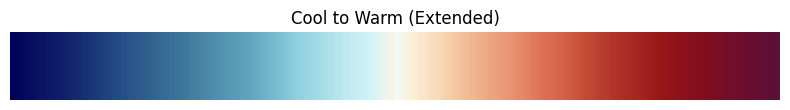

In [1]:
%env CUDA_VISIBLE_DEVICES = 5
import torch
import numpy as np
import matplotlib.pyplot as plt

from functools import partial
import sys
sys.path.append("../../..")
from ConditionalDiffusionGeneration.src.guided_diffusion.unet import create_model
from ConditionalDiffusionGeneration.src.guided_diffusion.condition_methods import get_conditioning_method
from ConditionalDiffusionGeneration.src.guided_diffusion.measurements import get_noise, get_operator
from ConditionalDiffusionGeneration.src.guided_diffusion.gaussian_diffusion import create_sampler
from einops import rearrange

torch.manual_seed(42)
np.random.seed(42)
if torch.cuda.is_available():
    dev = "cuda"
else:
    dev = "cpu"

device = torch.device(dev)
print(device)

from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]


rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)


x = rgb_points[:, 0]

r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]

colors = list(zip(x, zip(r, g, b)))

mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)
gradient = np.linspace(0, 1, 256).reshape(1, -1)
plt.figure(figsize=(8, 1.2))
plt.imshow(gradient, aspect='auto', cmap=mycmap)
plt.axis("off")
plt.title("Cool to Warm (Extended)")
plt.tight_layout()
plt.show()

### Load Unconditional Model

In [33]:
u_net_model = create_model(image_size= 64,
                           num_channels= 64,
                           num_res_blocks= 2,
                           num_heads=8,
                           num_head_channels=32,
                           attention_resolutions="32,16,8,4,2,1",
                           channel_mult="1,1,2,2,4,4",
                           learn_sigma=True,
                           model_path='../../../UnconditionalDiffusionTraining_and_Generation/output/logs_unet_experiment1/ema.pt'
                        )

u_net_model.to(device)
u_net_model.eval()
print('loaded unet')

loaded unet


## **Condition**: low-resolution or noisy $S_g$ (time-lapse seismic monitoring)

### Conditional Operator and Noise

In [34]:
operator =  get_operator(name='cartesian_superresolution',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1999,
                        ds_size=16,
                        vanilla_flag=True,
                        )

/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:666: UserWarning: Vanilla flag is set to True, using the original data without downsampling!
  warnings.warn(f"Vanilla flag is set to True, using the original data without downsampling!")


Simulation data loaded, with shape (64, 64, 64, 3)


In [35]:
noiser = get_noise(sigma=0.0, name='gaussian')

### Conditioning Method

In [36]:
cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='vanilla', scale=0.0)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

### Sampler

In [37]:
sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

### Generate Samples

In [ ]:
no_of_samples = 4
time_length = 64
latent_size = 256

In [ ]:
x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

In [40]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
torch.save(gen_latents, 'conditional_outputs/pts/generated_latents_Unconditional2.pt')

Generated latents shape: torch.Size([4, 64, 256])


### Decoding latents to flow fields

In [41]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [42]:
# gen_latents = torch.load('conditional_outputs/pts/generated_latents_Cart8xSR.pt')
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Unconditional2.pt')

CNF output shape: torch.Size([4, 64, 64, 64, 3])


### ***Load pt records (CNF out & reference)***

In [12]:
sr4 = torch.load('conditional_outputs/pts/CNF_out_Cart4xSR.pt', map_location='cpu').detach().numpy()
sr8 = torch.load('conditional_outputs/pts/CNF_out_Cart8xSR.pt', map_location='cpu').detach().numpy()
sr16 = torch.load('conditional_outputs/pts/CNF_out_Cart16xSR.pt', map_location='cpu').detach().numpy()
sr64 = torch.load('conditional_outputs/pts/CNF_out_Cart64xSR.pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {sr16.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


*plot maps*

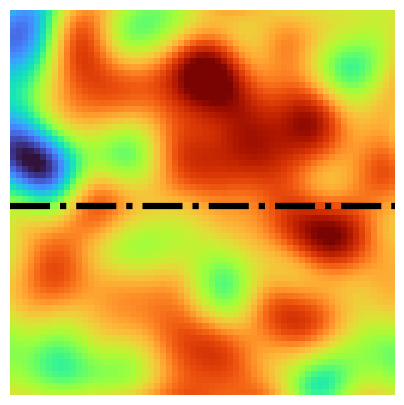

In [ ]:
plt.figure(figsize=(5, 5))
plt.imshow(ref[0, :, :, -1], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.axhline(y=32, color='k', linestyle='-.', linewidth=4.5)
plt.savefig('conditional_outputs/figs/Ref_cart_K.pdf', bbox_inches='tight')

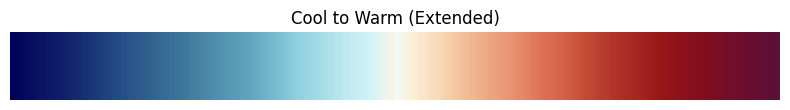

In [25]:
from matplotlib.colors import LinearSegmentedColormap
import json

with open("../cmap.json", "r") as f:
    cmap_json = json.load(f)[0]


rgb_points = np.array(cmap_json["RGBPoints"]).reshape(-1, 4)


x = rgb_points[:, 0]

r = rgb_points[:, 1]
g = rgb_points[:, 2]
b = rgb_points[:, 3]

colors = list(zip(x, zip(r, g, b)))

mycmap = LinearSegmentedColormap.from_list("CoolToWarmExtended", colors)
gradient = np.linspace(0, 1, 256).reshape(1, -1)
plt.figure(figsize=(8, 1.2))
plt.imshow(gradient, aspect='auto', cmap=mycmap)
plt.axis("off")
plt.title("Cool to Warm (Extended)")
plt.tight_layout()
plt.show()

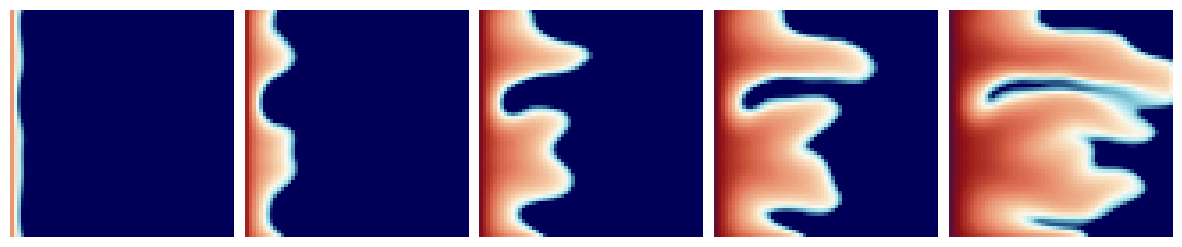

In [ ]:
# time steps: 500 days / 64 steps = 7.8 days/step
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(ref[t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs/Ref_cart_Sg.pdf', bbox_inches='tight')

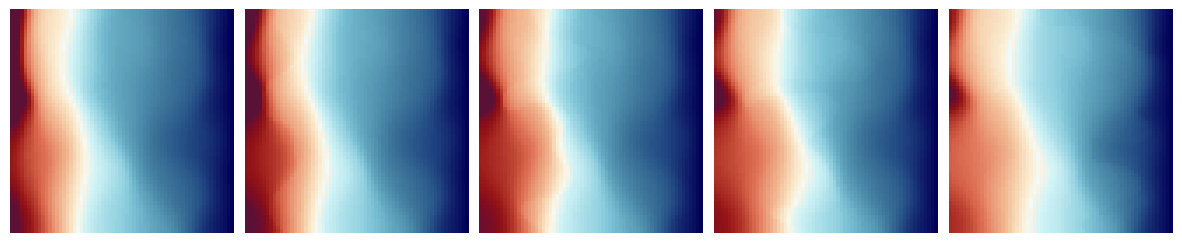

In [ ]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(ref[t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=15)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs/Ref_cart_P.pdf', bbox_inches='tight')

In [92]:
def downsample(numpy_array, ds_size):
    assert len(numpy_array.shape) >= 3, "Input array must have at least 3 dimensions"
    import torch.nn.functional as F
    ds_size = (ds_size, ds_size) if isinstance(ds_size, int) else tuple(ds_size)
    to_tensor = torch.from_numpy(numpy_array)
    print(f"Before downsample shape: {to_tensor.shape}")
    ds_tensor = F.interpolate(to_tensor, size=ds_size, mode='nearest')
    print(f"After downsample shape: {ds_tensor.shape}")
    return ds_tensor.numpy()

SR4 K shape: (10, 64, 64)


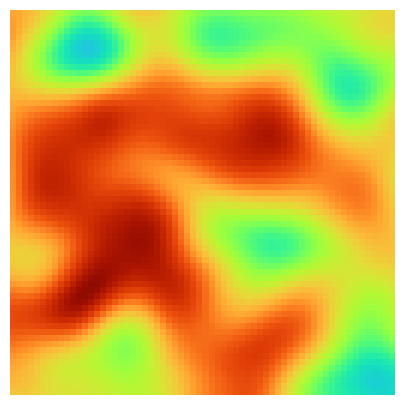

In [93]:
sr4_k = np.mean(sr4[..., -1], axis=1)
print(f"SR4 K shape: {sr4_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sr4_k[0, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs/Gene_cart_K_sr4.pdf', bbox_inches='tight')

Before downsample shape: torch.Size([10, 64, 64, 64])
After downsample shape: torch.Size([10, 64, 4, 4])
SR4 Sg shape: (10, 64, 64, 64), downsampled SR4 Sg shape: (10, 64, 4, 4)


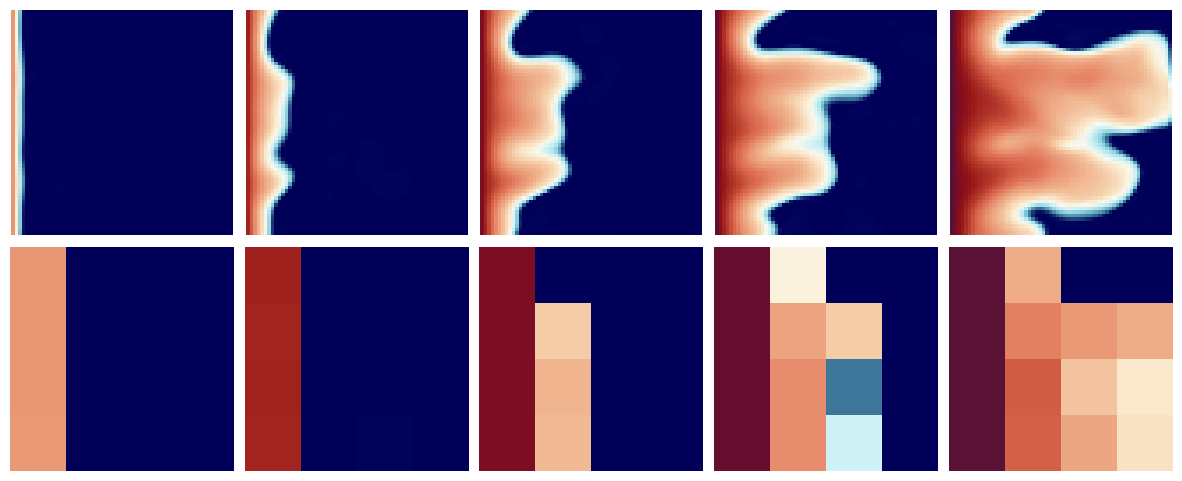

In [116]:
sr4_sg = sr4[..., 1]
sr4_sg_ds = downsample(sr4_sg, 4)
print(f"SR4 Sg shape: {sr4_sg.shape}, downsampled SR4 Sg shape: {sr4_sg_ds.shape}")
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[0, i].imshow(sr4_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(sr4_sg_ds[0, t, ...], cmap=mycmap, vmin=0, vmax=0.6)
    ax[0, i].axis('off')
    ax[1, i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_Sg_sr4.pdf', bbox_inches='tight')

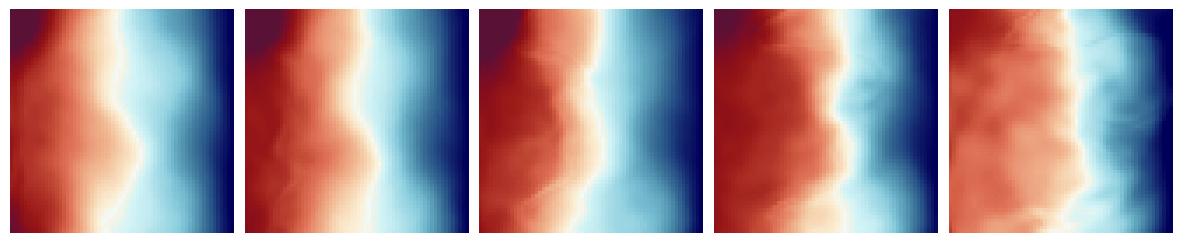

In [6]:
sr4_p = sr4[..., 0]
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[i].imshow(sr4_p[0, t, :, :]/1e6, cmap=mycmap, vmin=12, vmax=15)
    ax[i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_P_sr4.pdf', bbox_inches='tight')

SR8 K shape: (10, 64, 64)


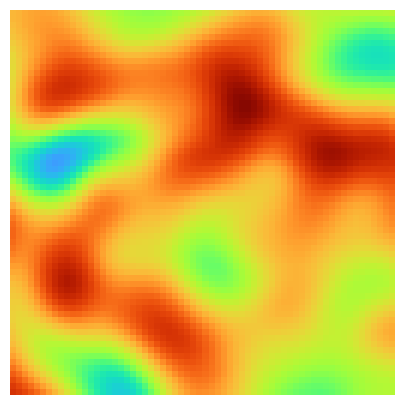

In [96]:
sr8_k = np.mean(sr8[..., -1], axis=1)
print(f"SR8 K shape: {sr8_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sr8_k[0, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs/Gene_cart_K_sr8.pdf', bbox_inches='tight')

Before downsample shape: torch.Size([10, 64, 64, 64])
After downsample shape: torch.Size([10, 64, 8, 8])
SR8 Sg shape: (10, 64, 64, 64), downsampled SR8 Sg shape: (10, 64, 8, 8)


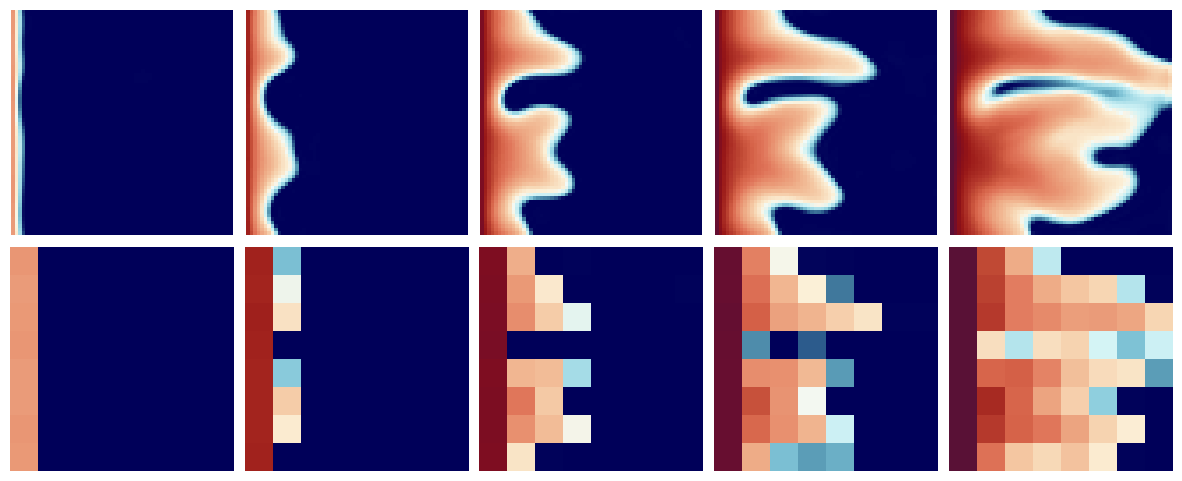

In [ ]:
sr8_sg = sr8[..., 1]
sr8_sg_ds = downsample(sr8_sg, 8)
print(f"SR8 Sg shape: {sr8_sg.shape}, downsampled SR8 Sg shape: {sr8_sg_ds.shape}")
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[0, i].imshow(sr8_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(sr8_sg_ds[0, t, ...], cmap=mycmap, vmin=0, vmax=0.6)
    ax[0, i].axis('off')
    ax[1, i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_Sg_sr8.pdf', bbox_inches='tight')

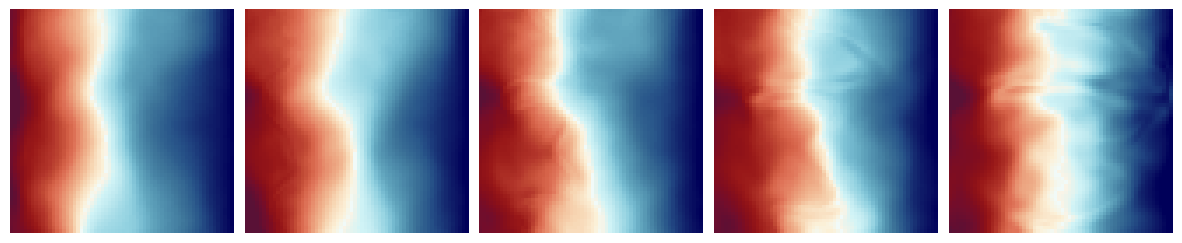

In [7]:
sr8_p = sr8[..., 0]

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[i].imshow(sr8_p[0, t, :, :]/1e6, cmap=mycmap, vmin=12, vmax=15)
    ax[i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_P_sr8.pdf', bbox_inches='tight')

SR16 K shape: (10, 64, 64)


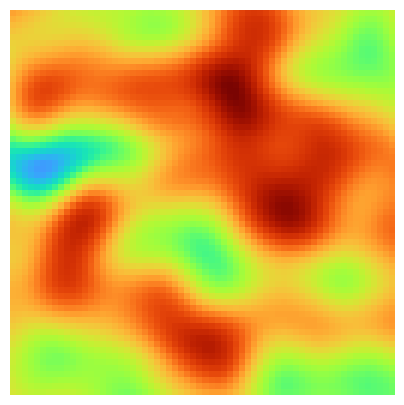

In [102]:
sr16_k = np.mean(sr16[..., -1], axis=1)
print(f"SR16 K shape: {sr16_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sr16_k[9, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs/Gene_cart_K_sr16.pdf', bbox_inches='tight')

Before downsample shape: torch.Size([10, 64, 64, 64])
After downsample shape: torch.Size([10, 64, 16, 16])
SR16 Sg shape: (10, 64, 64, 64), downsampled SR16 Sg shape: (10, 64, 16, 16)


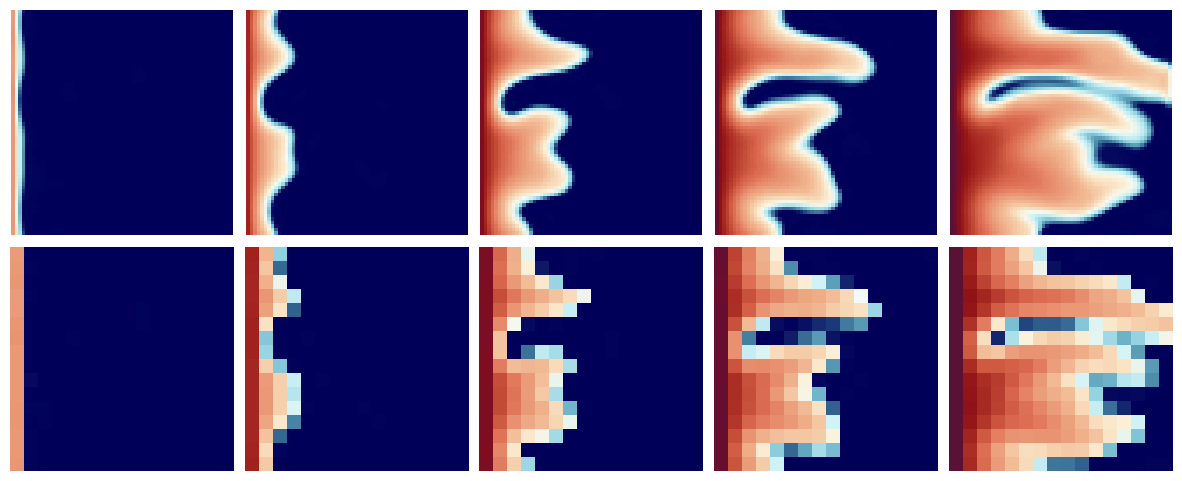

In [ ]:
sr16_sg = sr16[..., 1]
sr16_sg_ds = downsample(sr16_sg, 16)
print(f"SR16 Sg shape: {sr16_sg.shape}, downsampled SR16 Sg shape: {sr16_sg_ds.shape}")
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[0, i].imshow(sr16_sg[9, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(sr16_sg_ds[9, t, ...], cmap=mycmap, vmin=0, vmax=0.6)
    ax[0, i].axis('off')
    ax[1, i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_Sg_sr16.pdf', bbox_inches='tight')

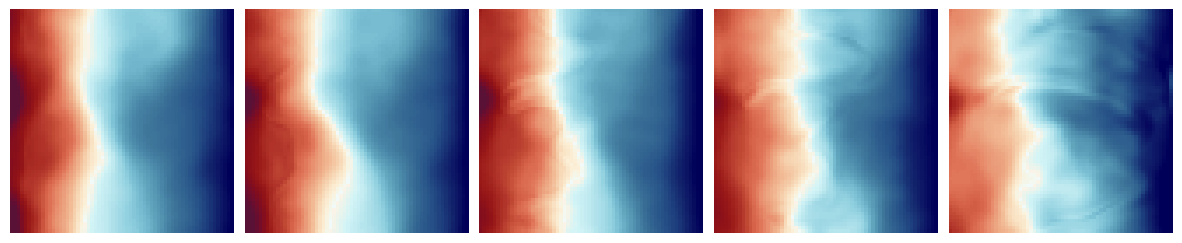

In [8]:
sr16_p = sr16[..., 0]

ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 6))
for i in range(5):
    t = ts[i]
    ax[i].imshow(sr16_p[9, t, :, :]/1e6, cmap=mycmap, vmin=12, vmax=15)
    ax[i].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
plt.savefig('conditional_outputs/figs/Gene_cart_P_sr16.pdf', bbox_inches='tight')

In [238]:
def plot_one_sample(gene_k, gene_sat, gene_pre, sample_idx):
    '''
    each input should be a list containing the 3 resolutions
    '''
    fig, ax = plt.subplots(3, 3, figsize=(6.5, 6), constrained_layout=True)
    for i in range(3):
        ax[0, i].imshow(gene_k[i][sample_idx, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
        ax[0, i].axis('off')
        if i == 0:
            ax[0, i].text(-0.05, 0.5, 'Permeability', va='center', ha='right',
                        fontsize=16, rotation=90, transform=ax[0, i].transAxes)
        ax[1, i].imshow(gene_sat[i][sample_idx, -1, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
        ax[1, i].axis('off')
        if i == 0:
            ax[1, i].text(-0.05, 0.5, 'Saturation', va='center', ha='right',
                        fontsize=16, rotation=90, transform=ax[1, i].transAxes)
        ax[2, i].imshow(gene_pre[i][sample_idx, -1, :, :]/1e6, cmap=mycmap, vmin=12, vmax=15)
        ax[2, i].axis('off')
        if i == 0:
            ax[2, i].text(-0.05, 0.5, 'Pressure', va='center', ha='right',
                        fontsize=16, rotation=90, transform=ax[2, i].transAxes)
    plt.savefig(f'conditional_outputs/figs/Gene_sample{sample_idx}@last.pdf', bbox_inches='tight')
    plt.show()

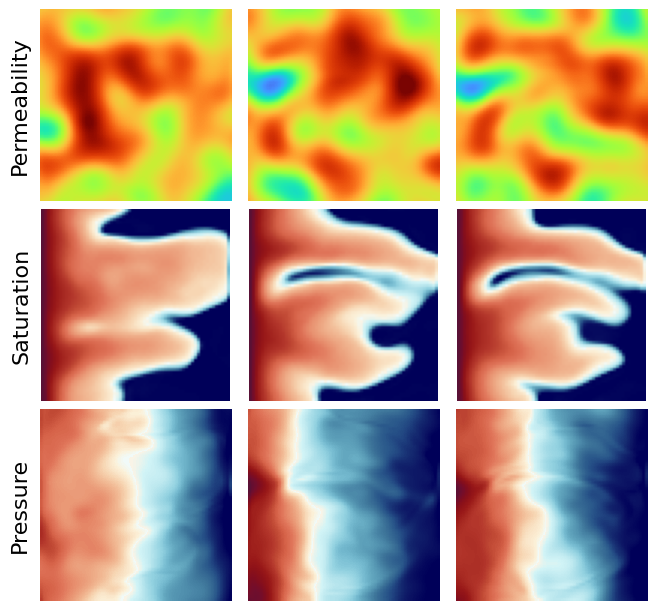

In [239]:
plot_one_sample(
    gene_k=[sr4_k, sr8_k, sr16_k],
    gene_sat=[sr4_sg, sr8_sg, sr16_sg],
    gene_pre=[sr4_p, sr8_p, sr16_p],
    sample_idx=2
)


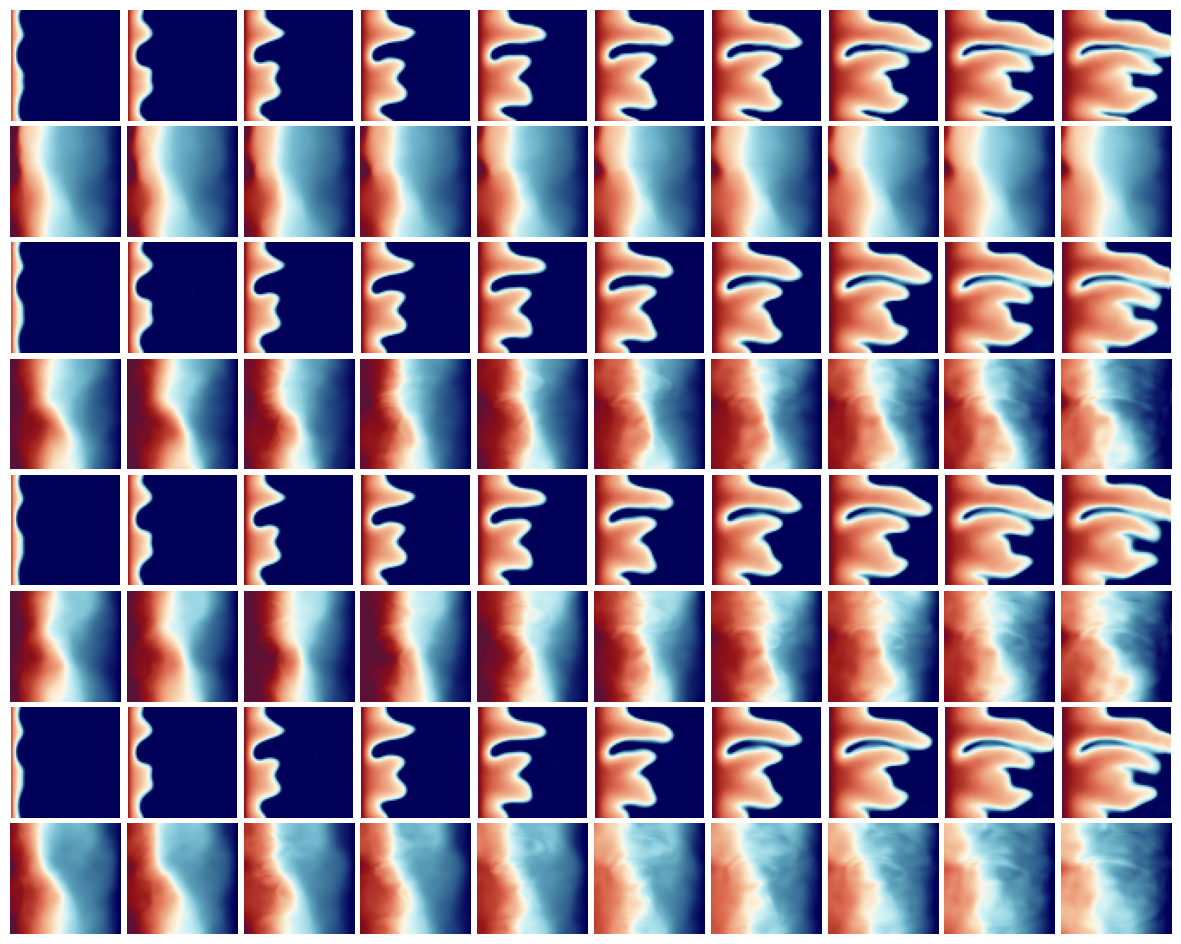

In [7]:
sr_16_sg = sr16[..., 1]
sr_16_p = sr16[..., 0]

days = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
ts = [int((d / (500 / 64))) for d in days]
ts[-1] = 63

fig, ax = plt.subplots(8, 10, figsize=(15, 12))
for i in range(10):
    t = ts[i]
    ax[0, i].imshow(ref[t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(ref[t, ..., 0], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[2, i].imshow(sr_16_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[3, i].imshow(sr_16_p[0, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[4, i].imshow(sr_16_sg[3, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[5, i].imshow(sr_16_p[3, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[6, i].imshow(sr_16_sg[6, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[7, i].imshow(sr_16_p[6, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)

for row in range(8):
    for col in range(10):
        ax[row, col].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
# plt.tight_layout()
plt.savefig('conditional_outputs/more_results/SR.pdf', bbox_inches='tight')

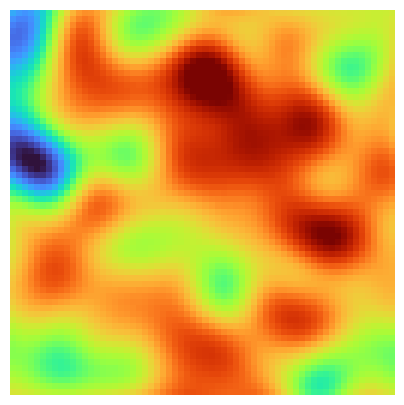

In [13]:
plt.figure(figsize=(5, 5))
plt.imshow(ref[0, :, :, -1], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
# plt.axhline(y=32, color='k', linestyle='-.', linewidth=4.5)
plt.savefig('conditional_outputs/more_results/SR_ref_K.pdf', bbox_inches='tight')

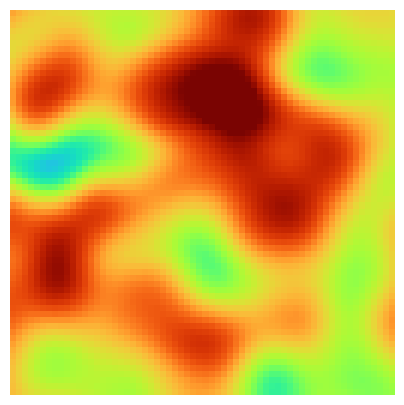

In [25]:
sr16_k = np.mean(sr16[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(sr16_k[6, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/more_results/SR_K3.pdf', bbox_inches='tight')

Unconditinal generation

(4, 64, 64, 64, 3)


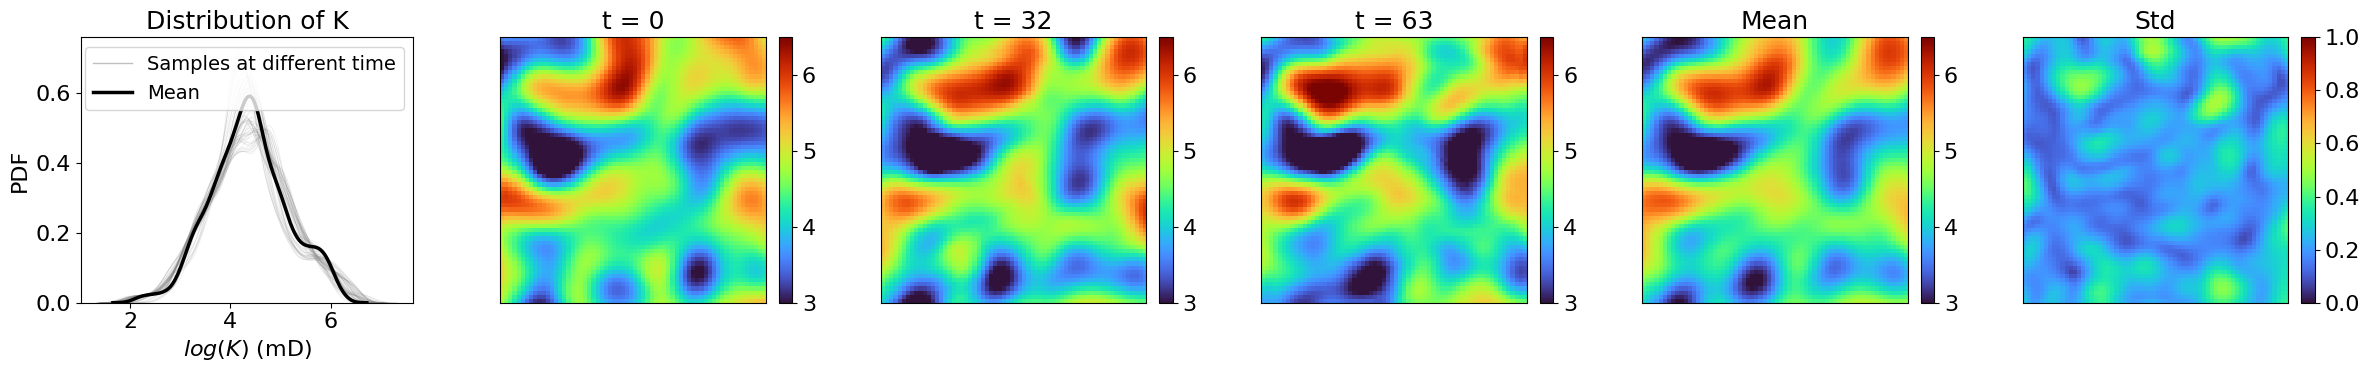

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.lines import Line2D

plt.rcParams.update({
    'font.size': 16,
    'axes.titlesize': 18,
    'axes.labelsize': 16,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'legend.fontsize': 14,
})

uncond = torch.load('conditional_outputs/pts/CNF_out_Unconditional2.pt', map_location='cpu').detach().numpy()
print(uncond.shape)

data = uncond[2, :, :, :, 2]  # shape: (num_samples, H, W)
num_samples = data.shape[0]
mean = np.mean(data, axis=0)
std = np.std(data, axis=0)

# Pick 1st, middle, last time step
idx = [0, num_samples // 2, num_samples - 1]

fig, axes = plt.subplots(1, 6, figsize=(24, 4))

# --- Axis 0: KDE distribution ---
for i in range(num_samples):
    sns.kdeplot(data[i].flatten(), fill=False, alpha=0.15, color='gray', linewidth=0.5, ax=axes[0])
sns.kdeplot(mean.flatten(), fill=False, color='black', linewidth=2.5, ax=axes[0])
handles = [
    Line2D([0], [0], color='gray', linewidth=1, alpha=0.5),
    Line2D([0], [0], color='black', linewidth=2.5),
]
axes[0].legend(handles, ['Samples at different time', 'Mean'])
axes[0].set_xlabel('$log(K)$ (mD)')
axes[0].set_ylabel('PDF')
axes[0].set_title('Distribution of K')

# --- Axes 1-3: 3 sample snapshots ---
for j, i in enumerate(idx):
    im = axes[j + 1].imshow(data[i], cmap='turbo', vmin=3, vmax=6.5)
    axes[j + 1].set_title(f't = {i}')
    fig.colorbar(im, ax=axes[j + 1], fraction=0.046, pad=0.04)
    axes[j + 1].set_xticks([])
    axes[j + 1].set_yticks([])

# --- Axis 4: Mean contour ---
im1 = axes[4].imshow(mean, cmap='turbo', vmin=3, vmax=6.5)
axes[4].set_title('Mean')
fig.colorbar(im1, ax=axes[4], fraction=0.046, pad=0.04)
axes[4].set_xticks([])
axes[4].set_yticks([])

# --- Axis 5: Std contour ---
im2 = axes[5].imshow(std, cmap='turbo', vmin=0, vmax=1.0)
axes[5].set_title('Std')
fig.colorbar(im2, ax=axes[5], fraction=0.046, pad=0.04)
axes[5].set_xticks([])
axes[5].set_yticks([])

plt.tight_layout()
plt.savefig('conditional_outputs/Uncond/uncond_hist_mean_std_rebuttle.pdf', bbox_inches='tight')
plt.show()


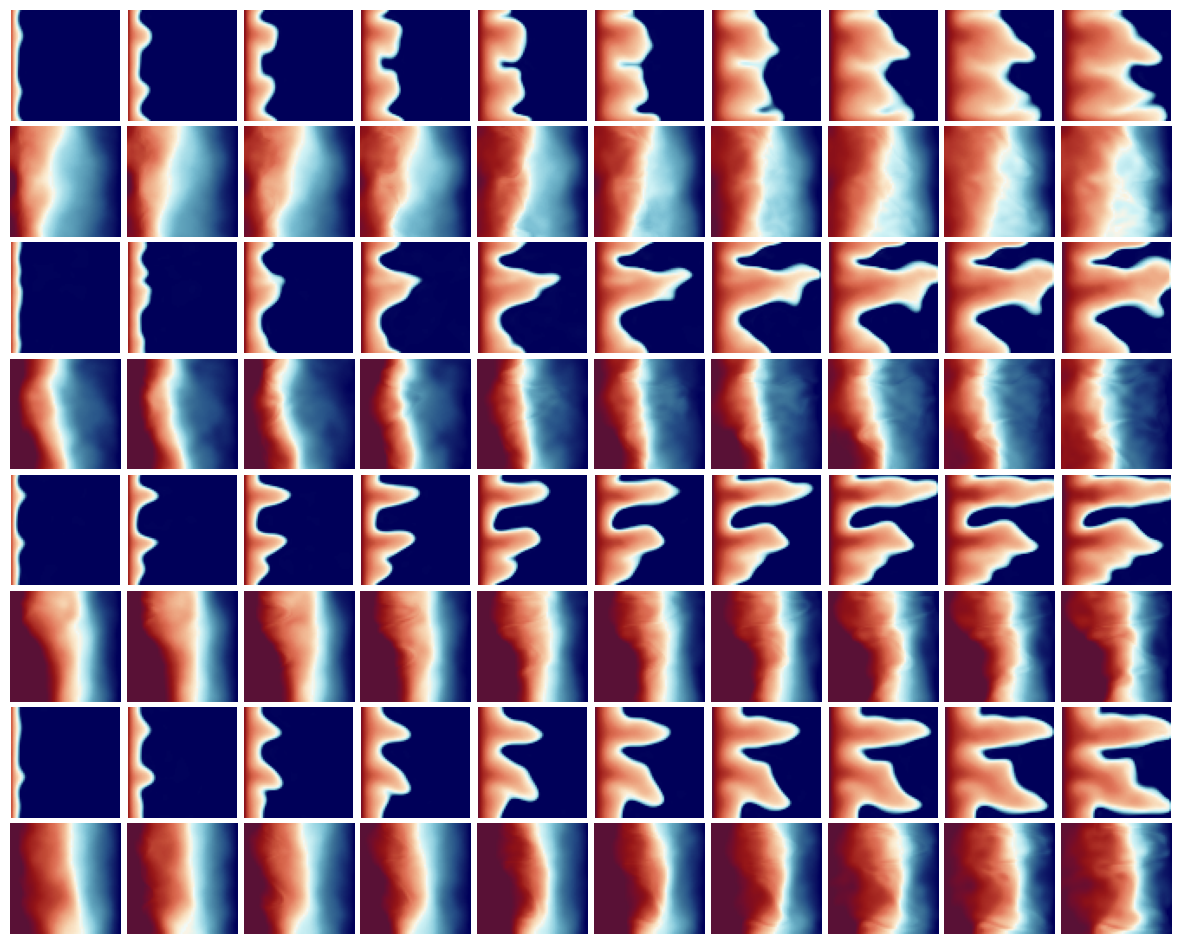

In [14]:
uncond = torch.load('conditional_outputs/pts/CNF_out_Unconditional.pt', map_location='cpu').detach().numpy()

sr_16_sg = uncond[..., 1]
sr_16_p = uncond[..., 0]

days = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
ts = [int((d / (500 / 64))) for d in days]
ts[-1] = 63

fig, ax = plt.subplots(8, 10, figsize=(15, 12))
for i in range(10):
    t = ts[i]
    ax[0, i].imshow(sr_16_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(sr_16_p[0, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[2, i].imshow(sr_16_sg[1, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[3, i].imshow(sr_16_p[1, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[4, i].imshow(sr_16_sg[2, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[5, i].imshow(sr_16_p[2, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[6, i].imshow(sr_16_sg[3, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[7, i].imshow(sr_16_p[3, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)

for row in range(8):
    for col in range(10):
        ax[row, col].axis('off')

plt.subplots_adjust(wspace=0.05, hspace=0.05)
# plt.tight_layout()
plt.savefig('conditional_outputs/Uncond/uncond.pdf', bbox_inches='tight')

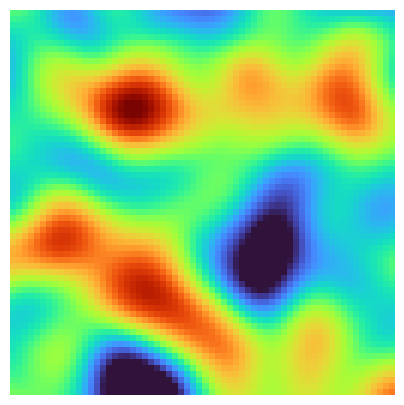

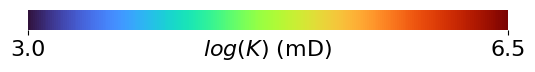

In [29]:
sr16_k = np.mean(uncond[..., -1], axis=1)
plt.figure(figsize=(5, 5))
plt.imshow(sr16_k[3, :, :], cmap='turbo', vmin=3.0, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/Uncond/K4.pdf', bbox_inches='tight')

import matplotlib.colors as colors
cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=3, vmax=6.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(6, 2))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

cbar.set_ticks([3.0, 6.5])
cbar.ax.set_xticklabels(["3.0", "6.5"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/Uncond/colorbar_K.pdf", bbox_inches='tight')
plt.show()

*Plot colorbars separately*

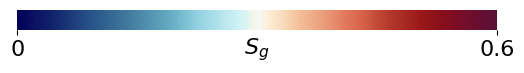

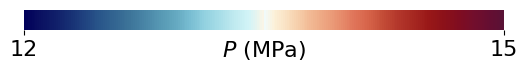

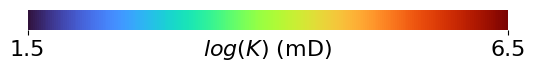

In [2]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.6)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(6, 2))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

cbar.set_ticks([0, 0.6])
cbar.ax.set_xticklabels(["0", "0.6"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs/colorbar_Sg.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = mycmap
norm = colors.Normalize(vmin=12, vmax=15)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(6, 2))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

cbar.set_ticks([12, 15])
cbar.ax.set_xticklabels(["12", "15"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$P$ (MPa)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs/colorbar_P.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=1.5, vmax=6.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(6, 2))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')

cbar.set_ticks([1.5, 6.5])
cbar.ax.set_xticklabels(["1.5", "6.5"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs/colorbar_K.pdf", bbox_inches='tight')
plt.show()

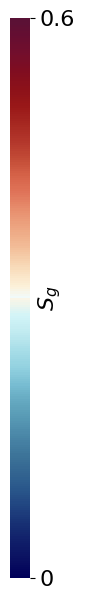

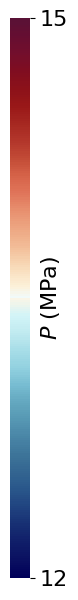

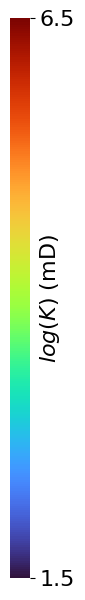

In [247]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.6)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([0, 0.6])
cbar.ax.set_yticklabels(["0", "0.6"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("conditional_outputs/figs/colorbar_Sg_long.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = mycmap
norm = colors.Normalize(vmin=12, vmax=15)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([12, 15])
cbar.ax.set_yticklabels(["12", "15"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$P$ (MPa)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("conditional_outputs/figs/colorbar_P_long.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=1.5, vmax=6.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(2, 7))
cbar_ax = fig.add_axes([0.5, 0.2, 0.1, 0.8])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='vertical')

cbar.set_ticks([1.5, 6.5])
cbar.ax.set_yticklabels(["1.5", "6.5"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(2, 0.5, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center', rotation='vertical')

plt.savefig("conditional_outputs/figs/colorbar_K_long.pdf", bbox_inches='tight')
plt.show()

*plot statistical*

In [ ]:
from skimage.metrics import structural_similarity as ssim
ref_k = ref[0, :, :, -1]
print(f"Reference K shape: {ref_k.shape}, SR4 K shape: {sr4_k.shape}, SR8 K shape: {sr8_k.shape}, SR16 K shape: {sr16_k.shape}")

In [143]:
def compute_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_value = ssim(ref, gen[i, :, :], data_range=gen[i, :, :].max() - gen[i, :, :].min())
        ssim_values.append(ssim_value)
    return np.array(ssim_values)

In [144]:
sr4_k_ssim = compute_ssim(ref_k, sr4_k)
sr8_k_ssim = compute_ssim(ref_k, sr8_k)
sr16_k_ssim = compute_ssim(ref_k, sr16_k)
print(f"SR4 K SSIM: {sr4_k_ssim}, \nSR8 K SSIM: {sr8_k_ssim}, \nSR16 K SSIM: {sr16_k_ssim}")

SR4 K SSIM: [0.19401002 0.31534705 0.22791163 0.29727367 0.25212027 0.34504898
 0.32837516 0.36046009 0.25809255 0.21446125], 
SR8 K SSIM: [0.5936494  0.5821021  0.55480961 0.49724701 0.57947699 0.57808239
 0.5638979  0.52986571 0.56730885 0.58412021], 
SR16 K SSIM: [0.60251801 0.59093278 0.60964483 0.62155803 0.6118145  0.62350572
 0.61145446 0.62343845 0.63200265 0.62812577]


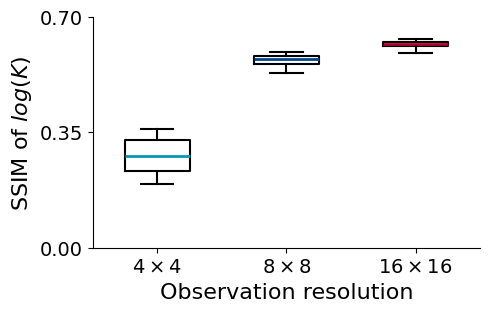

In [258]:
plt.figure(figsize=(5, 3))
bp = plt.boxplot([sr4_k_ssim, sr8_k_ssim, sr16_k_ssim], positions=[1, 2, 3], widths=0.5, showfliers=False, patch_artist=False,)

colors = ['#0499b4', '#00468c', '#ae002a']

for i, median in enumerate(bp['medians']):
    median.set(color=colors[i], linewidth=2)
for patch in bp['boxes']:
    patch.set_linewidth(1.5)
for whisker in bp['whiskers']:
    whisker.set(color='k', linewidth=1.5)
for cap in bp['caps']:
    cap.set(color='k', linewidth=1.5)

plt.xticks([1, 2, 3], [r'$4\times4$', r'$8\times8$', r'$16\times16$'], fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.1, 0.7)
plt.yticks([0.0, 0.35, 0.7])
plt.ylabel('SSIM of $log(K)$', fontsize=16)
plt.xlabel('Observation resolution', fontsize=16)
# plt.title('SSIM of $log(K)$ for different observation resolutions', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/figs/SSIM_Cart_SR_K.pdf', bbox_inches='tight')
plt.show()

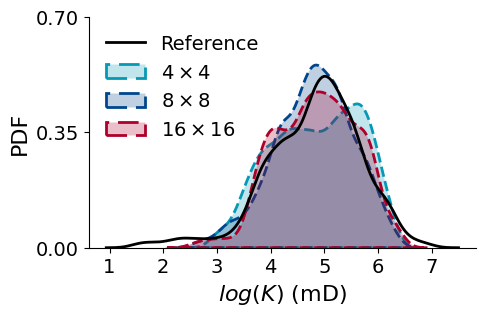

In [236]:
sr4_k_hist = sr4_k[0]
sr8_k_hist = sr8_k[0]
sr16_k_hist = sr16_k[9]

plt.figure(figsize=(5, 3))
colors = ['#0499b4', '#00468c', '#ae002a']
import seaborn as sns
sns.kdeplot(ref_k.flatten(), color='black', label='Reference', linewidth=2, fill=False, ls='-')
sns.kdeplot(sr4_k_hist.flatten(), color=colors[0], label=r'$4\times4$', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr8_k_hist.flatten(), color=colors[1], label=r'$8\times8$', linewidth=2, fill=True, ls='--')
sns.kdeplot(sr16_k_hist.flatten(), color=colors[2], label=r'$16\times16$', linewidth=2, fill=True, ls='--')
# plt.xlim(1.5, 6.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 0.7)
plt.yticks([0, 0.35, 0.7])
plt.xlabel('$log(K)$ (mD)', fontsize=16)
plt.ylabel('PDF', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(fontsize=14, frameon=False, loc='upper left')
plt.savefig('conditional_outputs/figs/Hist_Cart_SR_K.pdf', bbox_inches='tight')
plt.show()

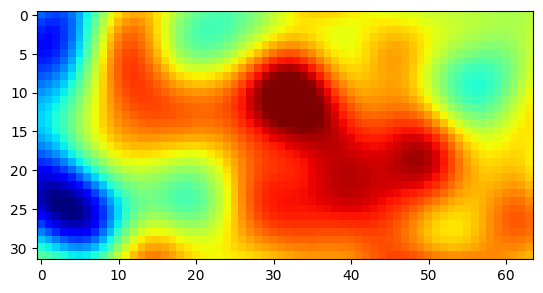

In [51]:
plt.imshow(ref_k[:32], cmap='jet', vmin=1.5, vmax=6.5)

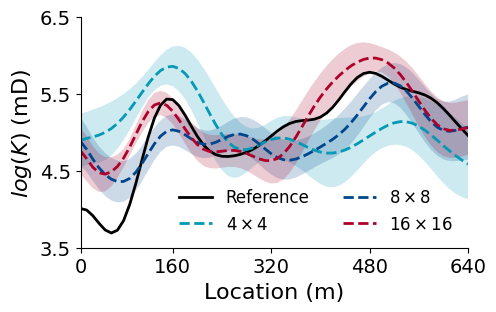

In [264]:
row_idx = 32
ref_k_line = ref[0, row_idx, :, -1]
sr4_k_line = sr4_k[:, row_idx, :]
sr8_k_line = sr8_k[:, row_idx, :]
sr16_k_line = sr16_k[:, row_idx, :]

def compute_mean_std(data):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    return mean, std
def plot_line_and_fill(data, color, label):
    mean, std = compute_mean_std(data)
    plt.plot(range(64), mean, color=color, linewidth=2, ls='--', label=label)
    plt.fill_between(range(64), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')

colors = ['#0499b4', '#00468c', '#ae002a']
plt.figure(figsize=(5, 3))
plt.plot(ref_k_line, color='black', label='Reference', linewidth=2, ls='-')
plot_line_and_fill(sr4_k_line, colors[0], r'$4\times4$')
plot_line_and_fill(sr8_k_line, colors[1], r'$8\times8$')
plot_line_and_fill(sr16_k_line, colors[2], r'$16\times16$')

plt.xlim(0, 63)
plt.ylim(3.5, 6.5)
plt.yticks([3.5, 4.5, 5.5, 6.5])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.legend(fontsize=12, frameon=False, ncols=2)
plt.savefig('conditional_outputs/figs/Line_spatial_K.pdf', bbox_inches='tight')
plt.show()

In [213]:
ref_sg = ref[:, :, :, 1]
print(f"Reference Sg shape: {ref_sg.shape}, SR4 Sg shape: {sr4_sg.shape}, SR8 Sg shape: {sr8_sg.shape}, SR16 Sg shape: {sr16_sg.shape}")

Reference Sg shape: (64, 64, 64), SR4 Sg shape: (10, 64, 64, 64), SR8 Sg shape: (10, 64, 64, 64), SR16 Sg shape: (10, 64, 64, 64)


In [214]:
def compute_temporal_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref_sg[t, :, :], gen[i, t, :, :], data_range=gen[i, t, :, :].max() - gen[i, t, :, :].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)

In [215]:
sr4_sg_ssim = compute_temporal_ssim(ref_sg, sr4_sg)
sr8_sg_ssim = compute_temporal_ssim(ref_sg, sr8_sg)
sr16_sg_ssim = compute_temporal_ssim(ref_sg, sr16_sg)
print(f"SR4 Sg SSIM: {sr4_sg_ssim.shape}, \nSR8 Sg SSIM: {sr8_sg_ssim.shape}, \nSR16 Sg SSIM: {sr16_sg_ssim.shape}")

sr4_sg_ssim_mean = np.mean(sr4_sg_ssim, axis=0)
sr8_sg_ssim_mean = np.mean(sr8_sg_ssim, axis=0)
sr16_sg_ssim_mean = np.mean(sr16_sg_ssim, axis=0)

sr4_sg_ssim_std = np.std(sr4_sg_ssim, axis=0)
sr8_sg_ssim_std = np.std(sr8_sg_ssim, axis=0)
sr16_sg_ssim_std = np.std(sr16_sg_ssim, axis=0)

SR4 Sg SSIM: (10, 64), 
SR8 Sg SSIM: (10, 64), 
SR16 Sg SSIM: (10, 64)


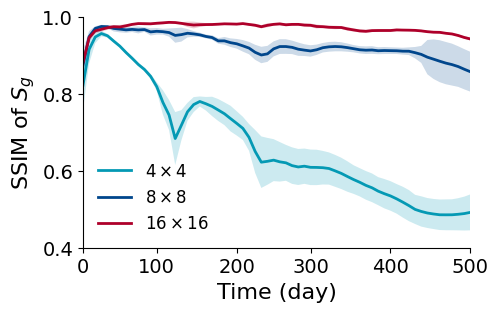

In [263]:
plt.figure(figsize=(5, 3))
colors = ['#0499b4', '#00468c', '#ae002a']
plt.plot(range(64), sr4_sg_ssim_mean, color=colors[0], linewidth=2, label=r'$4\times4$')
plt.fill_between(range(64), sr4_sg_ssim_mean - sr4_sg_ssim_std, sr4_sg_ssim_mean + sr4_sg_ssim_std, color=colors[0], alpha=0.2, edgecolor='none')
plt.plot(range(64), sr8_sg_ssim_mean, color=colors[1], linewidth=2, label=r'$8\times8$')
plt.fill_between(range(64), sr8_sg_ssim_mean - sr8_sg_ssim_std, sr8_sg_ssim_mean + sr8_sg_ssim_std, color=colors[1], alpha=0.2, edgecolor='none')
plt.plot(range(64), sr16_sg_ssim_mean, color=colors[2], linewidth=2, label=r'$16\times16$')
plt.fill_between(range(64), sr16_sg_ssim_mean - sr16_sg_ssim_std, sr16_sg_ssim_mean + sr16_sg_ssim_std, color=colors[2], alpha=0.2, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.4, 1.0)
plt.yticks([0.4, 0.6, 0.8, 1.0])
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('SSIM of $S_g$', fontsize=16)
plt.legend(fontsize=12, frameon=False, loc='lower left')
plt.xlim(0, 63)
plt.ylim(top=1)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('conditional_outputs/figs/SSIM_Cart_SR_Sg.pdf', bbox_inches='tight')
plt.show()

SR4 Sg SSIM: (10, 64), 
SR8 Sg SSIM: (10, 64), 
SR16 Sg SSIM: (10, 64)


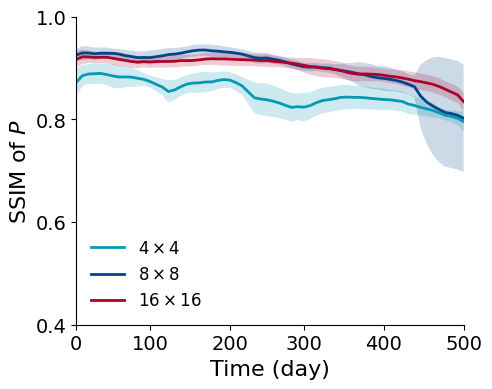

In [11]:
from skimage.metrics import structural_similarity as ssim
def compute_temporal_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref[t, :, :, 0], gen[i, t, :, :, 0], data_range=gen[i, t, :, :, 0].max() - gen[i, t, :, :, 0].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)


sr4_sg_ssim = compute_temporal_ssim(ref, sr4)
sr8_sg_ssim = compute_temporal_ssim(ref, sr8)
sr16_sg_ssim = compute_temporal_ssim(ref, sr16)
print(f"SR4 Sg SSIM: {sr4_sg_ssim.shape}, \nSR8 Sg SSIM: {sr8_sg_ssim.shape}, \nSR16 Sg SSIM: {sr16_sg_ssim.shape}")

sr4_sg_ssim_mean = np.mean(sr4_sg_ssim, axis=0)
sr8_sg_ssim_mean = np.mean(sr8_sg_ssim, axis=0)
sr16_sg_ssim_mean = np.mean(sr16_sg_ssim, axis=0)

sr4_sg_ssim_std = np.std(sr4_sg_ssim, axis=0)
sr8_sg_ssim_std = np.std(sr8_sg_ssim, axis=0)
sr16_sg_ssim_std = np.std(sr16_sg_ssim, axis=0)

plt.figure(figsize=(5, 4))
colors = ['#0499b4', '#00468c', '#ae002a']
plt.plot(range(64), sr4_sg_ssim_mean, color=colors[0], linewidth=2, label=r'$4\times4$')
plt.fill_between(range(64), sr4_sg_ssim_mean - sr4_sg_ssim_std, sr4_sg_ssim_mean + sr4_sg_ssim_std, color=colors[0], alpha=0.2, edgecolor='none')
plt.plot(range(64), sr8_sg_ssim_mean, color=colors[1], linewidth=2, label=r'$8\times8$')
plt.fill_between(range(64), sr8_sg_ssim_mean - sr8_sg_ssim_std, sr8_sg_ssim_mean + sr8_sg_ssim_std, color=colors[1], alpha=0.2, edgecolor='none')
plt.plot(range(64), sr16_sg_ssim_mean, color=colors[2], linewidth=2, label=r'$16\times16$')
plt.fill_between(range(64), sr16_sg_ssim_mean - sr16_sg_ssim_std, sr16_sg_ssim_mean + sr16_sg_ssim_std, color=colors[2], alpha=0.2, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.4, 1.0)
plt.yticks([0.4, 0.6, 0.8, 1.0])
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('SSIM of $P$', fontsize=16)
plt.legend(fontsize=12, frameon=False, loc='lower left')
plt.xlim(0, 63)
plt.ylim(top=1)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('conditional_outputs/figs/SSIM_Cart_SR_P.pdf', bbox_inches='tight')
plt.show()

## **Condition**: partial obervations of $S_g$ and $P$ (monitoring wells)

### Operator and Sampler

In [4]:
operator =  get_operator(name='cartesian_sparse_measurement',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=20,
                        )

query_pts = operator.query_points
np.save('conditional_outputs/npys/query_pts_cart_sparse20.npy', np.array(query_pts))

noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # \lambda=1
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                        steps=1000,
                        noise_schedule="cosine",
                        model_mean_type="epsilon",
                        model_var_type="learned_range",
                        dynamic_threshold=False,
                        clip_denoised=True,
                        rescale_timesteps=False,
                        timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)


/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:77: UserWarning: Randomly generated 20 points for measurement, please check the results.
  warnings.warn(f"Randomly generated {num_probed} points for measurement, please check the results.")


Simulation data loaded, with shape (64, 64, 64, 3)


In [95]:
print(operator.query_points)
np.save('conditional_outputs/npys/query_pts_cart_sparse20.npy', np.array(operator.query_points))

[(41, 1), (6, 4), (15, 53), (44, 57), (31, 33), (36, 50), (10, 35), (26, 18), (23, 62), (47, 38), (51, 8), (37, 9), (57, 24), (1, 43), (21, 19), (16, 25), (55, 46), (61, 49), (5, 14), (33, 29)]


### Generation

In [5]:
no_of_samples = 1
time_length = 64
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Measurement shape: torch.Size([64, 20])


  0%|          | 0/1000 [00:00<?, ?it/s]

### Save generated latents

In [34]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
torch.save(gen_latents, 'conditional_outputs/pts/generated_latents_Cart5Sparse.pt')

Generated latents shape: torch.Size([10, 64, 256])


### Deocding by CNF

In [35]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [36]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Cart5Sparse.pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


### ***Load CNF and plot***

In [4]:
sparse1 = torch.load('conditional_outputs/pts/CNF_out_Cart1Sparse.pt', map_location='cpu').detach().numpy()
sparse5 = torch.load('conditional_outputs/pts/CNF_out_Cart5Sparse.pt', map_location='cpu').detach().numpy()
sparse20 = torch.load('conditional_outputs/pts/CNF_out_Cart20Sparse.pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {sparse5.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


*plot maps*

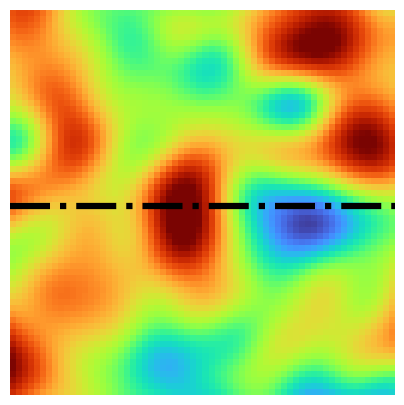

In [6]:
plt.figure(figsize=(5, 5))
plt.imshow(ref[0, :, :, -1], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.axhline(y=32, color='k', linestyle='-.', linewidth=4.5)
plt.savefig('conditional_outputs/figs_cart_sparse/Ref_cart_K_sparse_case.pdf', bbox_inches='tight')

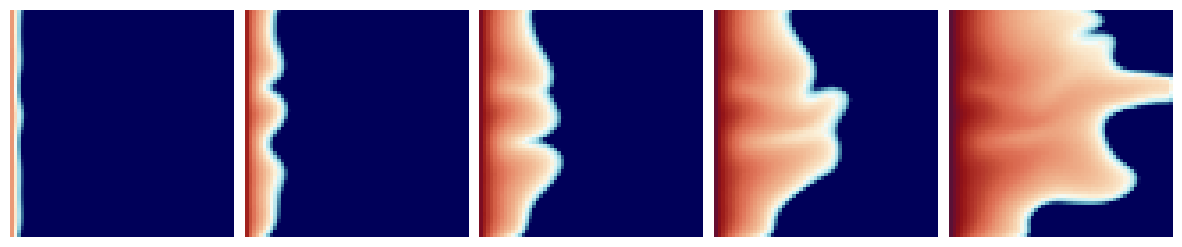

In [9]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(ref[t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Ref_cart_Sg_sparse_case.pdf', bbox_inches='tight')

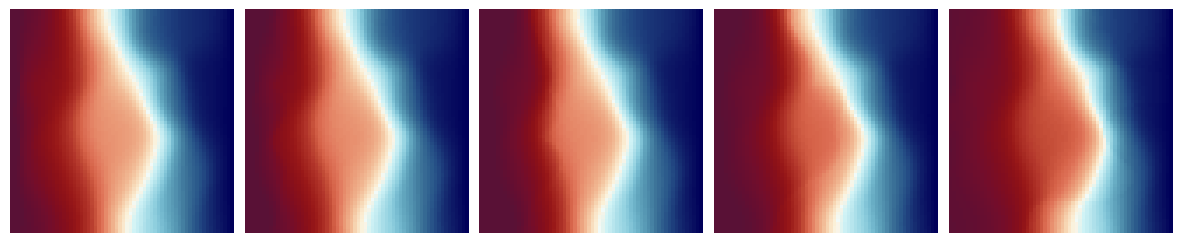

In [38]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(ref[t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Ref_cart_P_sparse_case.pdf', bbox_inches='tight')

Sparse1 K shape: (10, 64, 64)


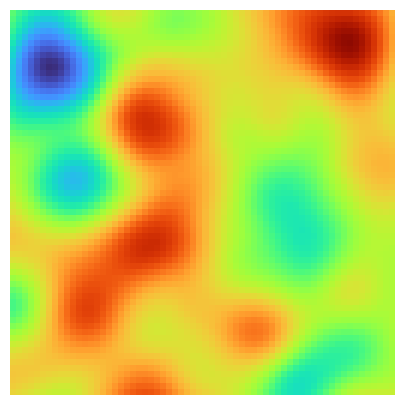

In [16]:
sparse1_k = np.mean(sparse1[..., -1], axis=1)
print(f"Sparse1 K shape: {sparse1_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sparse1_k[0, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse1.pdf', bbox_inches='tight')

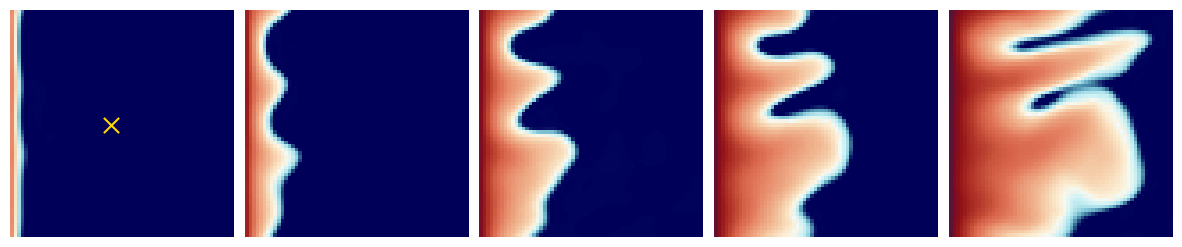

In [50]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
pts = [(32, 28)]
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse1[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse1.pdf', bbox_inches='tight')

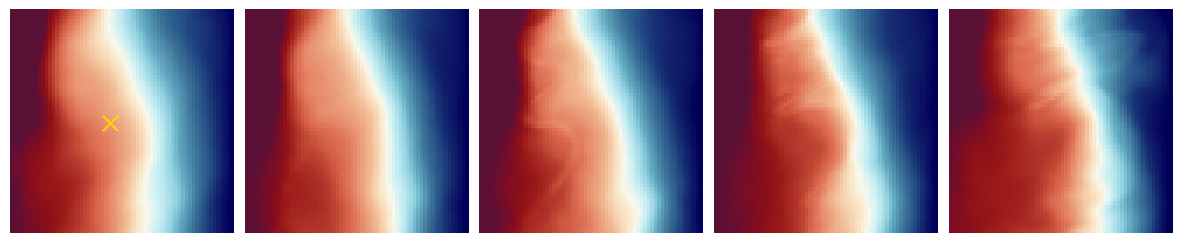

In [49]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(32, 28)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse1[0, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse1.pdf', bbox_inches='tight')

Sparse5 K shape: (10, 64, 64)


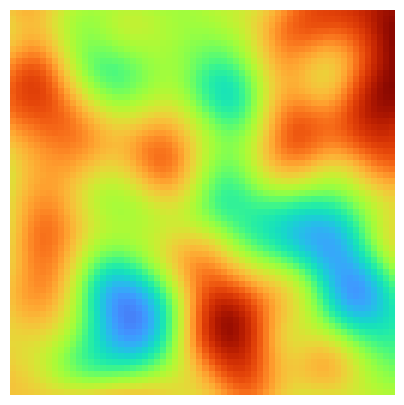

In [39]:
sparse5_k = np.mean(sparse5[..., -1], axis=1)
print(f"Sparse5 K shape: {sparse5_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sparse5_k[0, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse5.pdf', bbox_inches='tight')

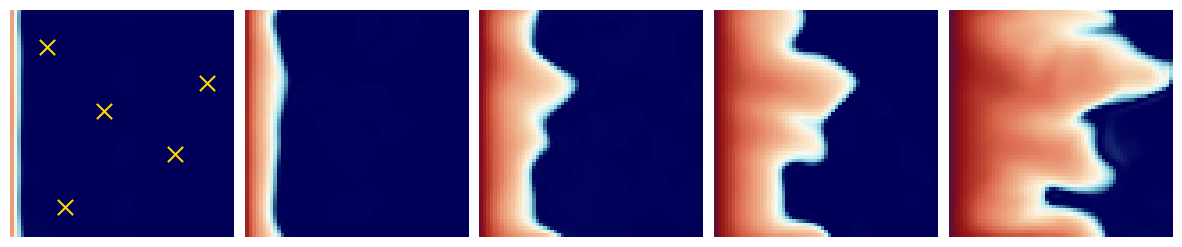

In [48]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse5[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse5.pdf', bbox_inches='tight')

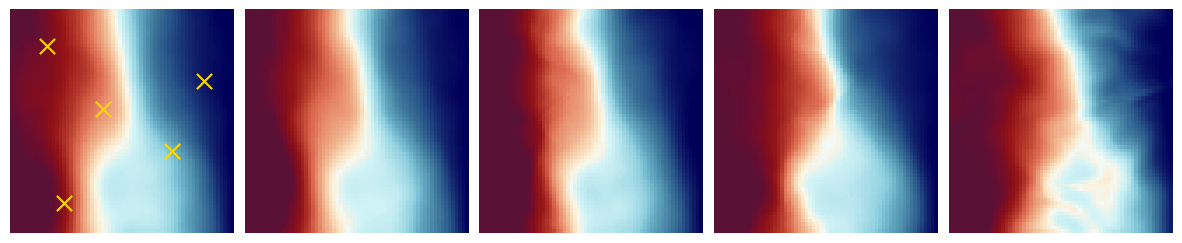

In [47]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse5[0, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse5.pdf', bbox_inches='tight')

Sparse20 K shape: (10, 64, 64)


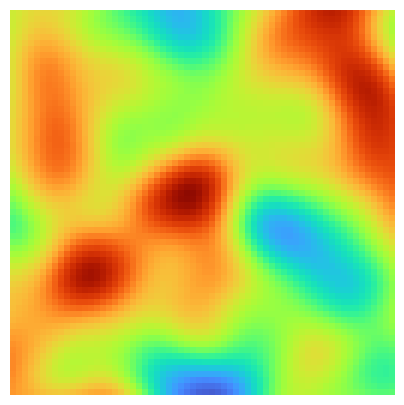

In [42]:
sparse20_k = np.mean(sparse20[..., -1], axis=1)
print(f"Sparse20 K shape: {sparse20_k.shape}")
plt.figure(figsize=(5, 5))
plt.imshow(sparse20_k[1, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse20.pdf', bbox_inches='tight')

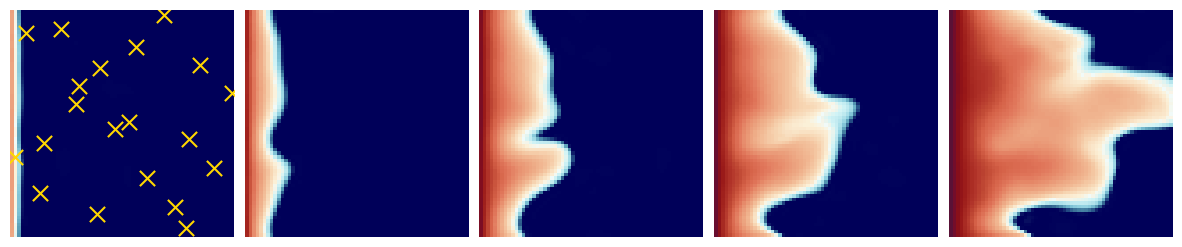

In [46]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse20[1, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse20.pdf', bbox_inches='tight')

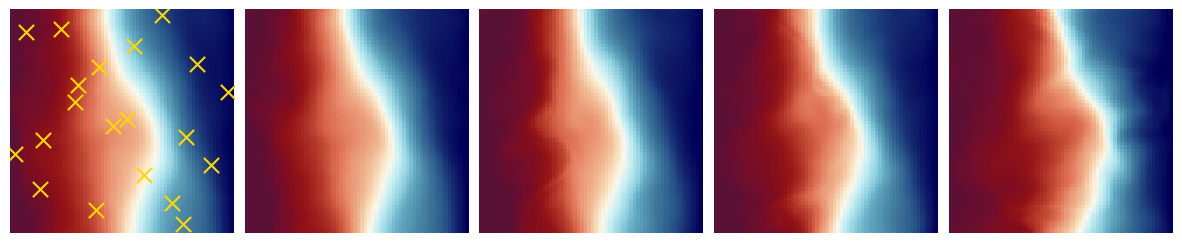

In [51]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse20[1, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse20.pdf', bbox_inches='tight')

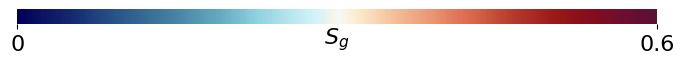

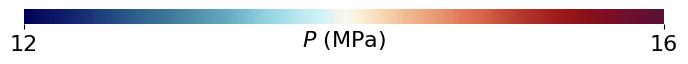

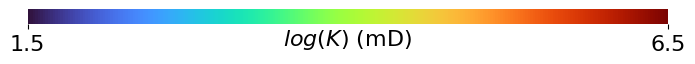

In [55]:
import matplotlib.colorbar as colorbar
import matplotlib.colors as colors

cmap = mycmap
norm = colors.Normalize(vmin=0, vmax=0.6)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([0, 0.6])
cbar.ax.set_xticklabels(["0", "0.6"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$S_g$", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs_cart_sparse/colorbar_Sg.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = mycmap
norm = colors.Normalize(vmin=12, vmax=16)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([12, 16])
cbar.ax.set_xticklabels(["12", "16"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$P$ (MPa)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs_cart_sparse/colorbar_P.pdf", bbox_inches='tight')
plt.show()

# -------------------------------------------

cmap = plt.get_cmap("turbo")
norm = colors.Normalize(vmin=1.5, vmax=6.5)
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])

fig = plt.figure(figsize=(8, 1.5))
cbar_ax = fig.add_axes([0.2, 0.5, 0.8, 0.1])

cbar = fig.colorbar(sm, cax=cbar_ax, orientation='horizontal')
cbar.set_ticks([1.5, 6.5])
cbar.ax.set_xticklabels(["1.5", "6.5"])
cbar.outline.set_visible(False)
cbar.ax.tick_params(labelsize=16)

cbar_ax.text(0.5, -1.0, "$log(K)$ (mD)", transform=cbar_ax.transAxes,
            fontsize=16, ha='center', va='center')

plt.savefig("conditional_outputs/figs_cart_sparse/colorbar_K.pdf", bbox_inches='tight')
plt.show()

## **Condition**: partial obervations of $S_g$, $P$, and $K$ (monitoring wells and well logs)

### Operator and Sampler

In [14]:
operator =  get_operator(name='cartesian_sparse_measurement_all',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=20,
                        )

query_pts = operator.query_points
np.save('conditional_outputs/npys/query_pts_cart_sparse20.npy', np.array(query_pts))

noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # \lambda=1
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                        steps=1000,
                        noise_schedule="cosine",
                        model_mean_type="epsilon",
                        model_var_type="learned_range",
                        dynamic_threshold=False,
                        clip_denoised=True,
                        rescale_timesteps=False,
                        timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

/ehome/zhao/nf/CoNFiLD/ConditionalDiffusionGeneration/inference_scripts/Case4/random_sensor/../../../../ConditionalDiffusionGeneration/src/guided_diffusion/measurements.py:211: UserWarning: Randomly generated 20 points for measurement, please check the results.
  warnings.warn(f"Randomly generated {num_probed} points for measurement, please check the results.")


Simulation data loaded, with shape (64, 64, 64, 3)


In [23]:
print(operator.query_points)

[(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]


### Generation

In [ ]:
no_of_samples = 10
time_length = 64
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

### Save generated latents

In [25]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")
torch.save(gen_latents, 'conditional_outputs/pts/generated_latents_Cart5Sparse_All.pt')

Generated latents shape: torch.Size([10, 64, 256])


### Decoding by CNF

In [26]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [27]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Cart5Sparse_All.pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


### ***Load CNF and plot***

In [15]:
sparse_all1 = torch.load('conditional_outputs/pts/CNF_out_Cart1Sparse_All.pt', map_location='cpu').detach().numpy()
sparse_all5 = torch.load('conditional_outputs/pts/CNF_out_Cart5Sparse_All.pt', map_location='cpu').detach().numpy()
sparse_all20 = torch.load('conditional_outputs/pts/CNF_out_Cart20Sparse_All.pt', map_location='cpu').detach().numpy()
ref = operator.simdata
print(f"Reference shape: {ref.shape}, CNF output shape: {sparse_all20.shape}")

Reference shape: (64, 64, 64, 3), CNF output shape: (10, 64, 64, 64, 3)


Sparse all1 K shape: (10, 64, 64)


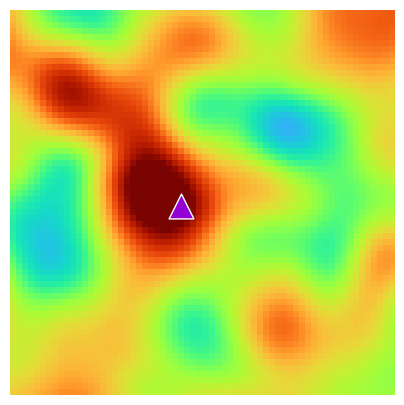

In [65]:
sparse_all1_k = np.mean(sparse_all1[..., -1], axis=1)
print(f"Sparse all1 K shape: {sparse_all1_k.shape}")
pts = [(32, 28)]
plt.figure(figsize=(5, 5))
plt.imshow(sparse_all1_k[0, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
for y, x in pts:
    plt.scatter(x, y, color='darkviolet', marker='^', s=320, edgecolors='white')
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse_all1.pdf', bbox_inches='tight')

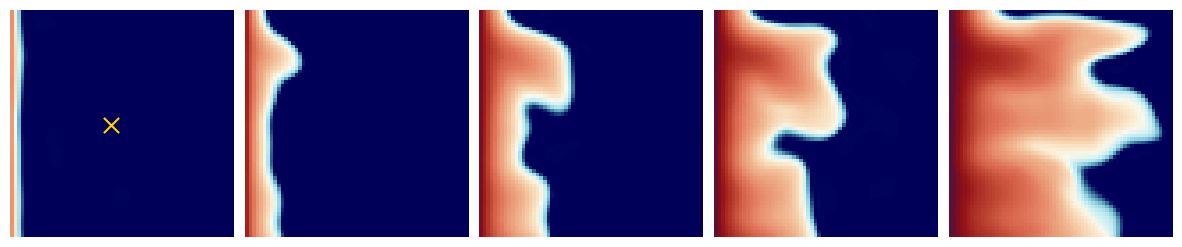

In [66]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
pts = [(32, 28)]
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all1[0, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
    
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse_all1.pdf', bbox_inches='tight')

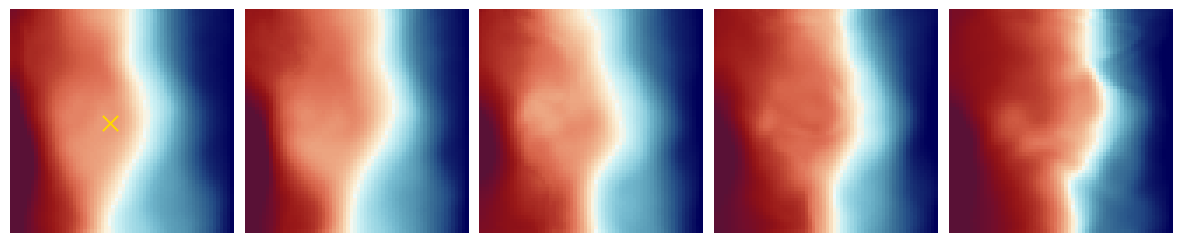

In [67]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(32, 28)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all1[0, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse_all1.pdf', bbox_inches='tight')

Sparse all5 K shape: (10, 64, 64)


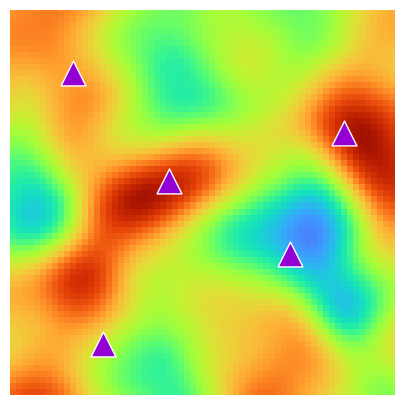

In [68]:
sparse_all5_k = np.mean(sparse_all5[..., -1], axis=1)
print(f"Sparse all5 K shape: {sparse_all5_k.shape}")
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]
plt.figure(figsize=(5, 5))
plt.imshow(sparse_all5_k[7, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
for y, x in pts:
    plt.scatter(x, y, color='darkviolet', marker='^', s=320, edgecolors='white')
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse_all5.pdf', bbox_inches='tight')

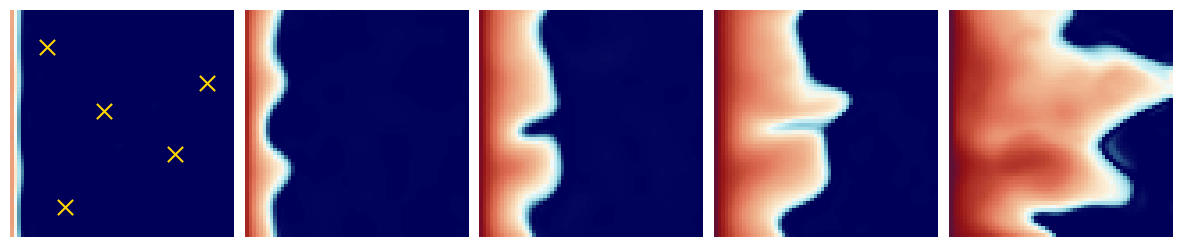

In [69]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all5[7, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse_all5.pdf', bbox_inches='tight')

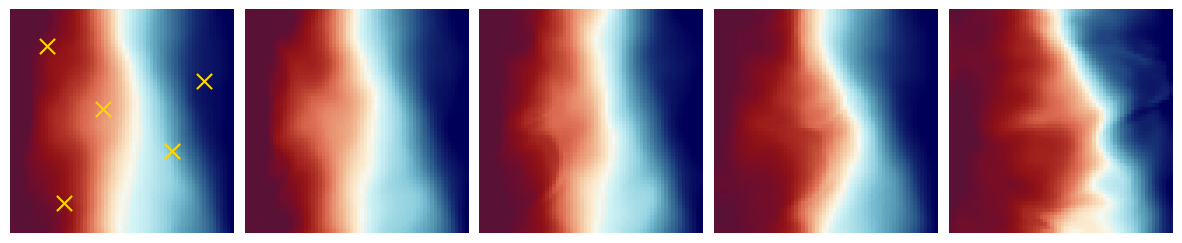

In [70]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = [(10, 10), (20, 55), (28, 26), (40, 46), (55, 15)]
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all5[7, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse_all5.pdf', bbox_inches='tight')

Sparse_all20 K shape: (10, 64, 64)


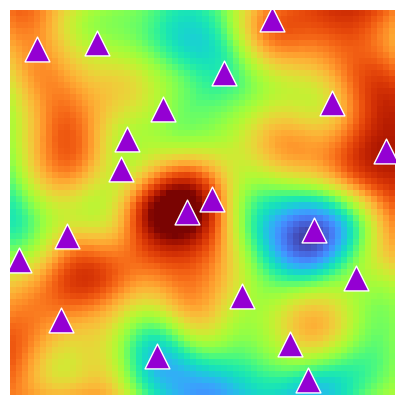

In [71]:
sparse_all20_k = np.mean(sparse_all20[..., -1], axis=1)
print(f"Sparse_all20 K shape: {sparse_all20_k.shape}")
query_pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
plt.figure(figsize=(5, 5))
plt.imshow(sparse_all20_k[1, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
for y, x in query_pts:
        plt.scatter(x, y, color='darkviolet', marker='^', s=320, edgecolors='white')
plt.axis('off')
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_K_sparse_all20.pdf', bbox_inches='tight')

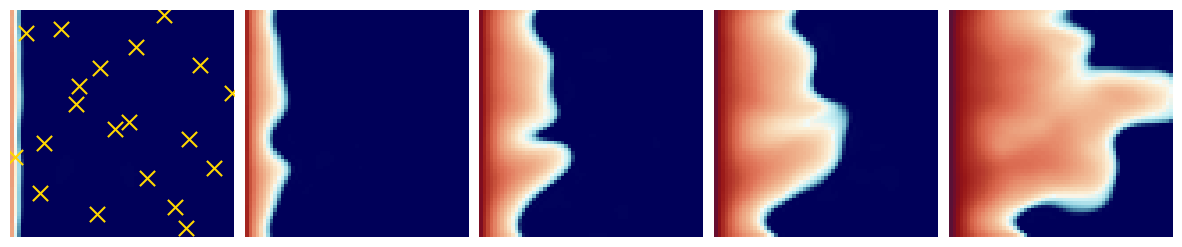

In [72]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all20[1, t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_Sg_sparse_all20.pdf', bbox_inches='tight')

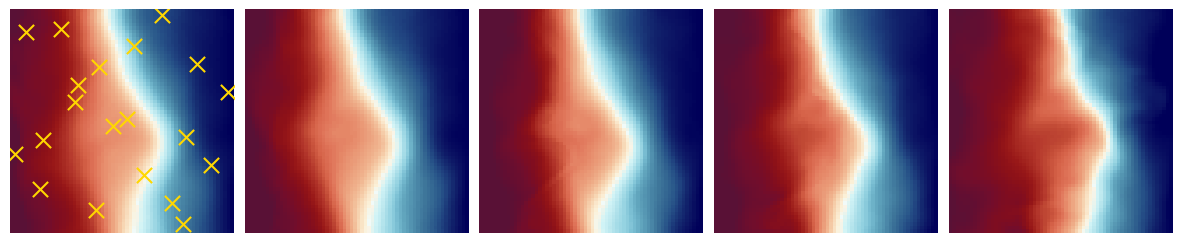

In [73]:
ts = [3, 12, 25, 38, 63]    # 30, 100, 200, 300, 500 days
days = [30, 100, 200, 300, 500]
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
fig, ax = plt.subplots(1, 5, figsize=(15, 5))
for i in range(5):
    t = ts[i]
    im = ax[i].imshow(sparse_all20[1, t, :, :, 0]/1e6, cmap=mycmap, vmin=12, vmax=16)
    if i == 0:
        for y, x in pts:
            ax[i].scatter(x, y, color='gold', marker='x', s=120)
    ax[i].axis('off')
    ax[i].set_xticks([])
    ax[i].set_yticks([])
plt.subplots_adjust(wspace=0.05)
plt.savefig('conditional_outputs/figs_cart_sparse/Gene_cart_P_sparse_all20.pdf', bbox_inches='tight')

## **Statistical analysis..**

**SSIM of K**

In [74]:
from skimage.metrics import structural_similarity as ssim

ref_k = ref[0, ..., -1]
print(f"reference K shape {ref_k.shape}")
print(f"Sparse K: {sparse1_k.shape}, Sparse all K: {sparse_all1_k.shape}")

def compute_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_value = ssim(ref, gen[i, :, :], data_range=gen[i, :, :].max() - gen[i, :, :].min())
        ssim_values.append(ssim_value)
    return np.array(ssim_values)

reference K shape (64, 64)
Sparse K: (10, 64, 64), Sparse all K: (10, 64, 64)


In [75]:
saprse1_k_ssim = compute_ssim(ref_k, sparse1_k)
sparse_all1_k_ssim = compute_ssim(ref_k, sparse_all1_k)
sparse5_k_ssim = compute_ssim(ref_k, sparse5_k)
sparse_all5_k_ssim = compute_ssim(ref_k, sparse_all5_k)
sparse20_k_ssim = compute_ssim(ref_k, sparse20_k)
sparse_all20_k_ssim = compute_ssim(ref_k, sparse_all20_k)

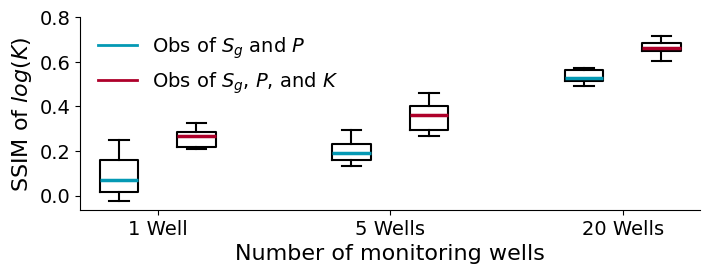

In [86]:
from matplotlib.lines import Line2D

plt.figure(figsize=(8, 2.5))
data = [saprse1_k_ssim, sparse_all1_k_ssim, sparse5_k_ssim, sparse_all5_k_ssim, sparse20_k_ssim, sparse_all20_k_ssim]
positions = [1, 2, 4, 5, 7, 8]

bp = plt.boxplot(data, positions=positions, widths=0.5, showfliers=False, patch_artist=False,)

colors = ['#0499b4', '#ae002a'] * 3

for i, median in enumerate(bp['medians']):
    median.set(color=colors[i], linewidth=2.5)
for patch in bp['boxes']:
    patch.set_linewidth(1.5)
for whisker in bp['whiskers']:
    whisker.set(color='k', linewidth=1.5)
for cap in bp['caps']:
    cap.set(color='k', linewidth=1.5)

plt.xticks([1.5, 4.5, 7.5], ['1 Well', '5 Wells', '20 Wells'], fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(top=0.8)
plt.ylabel('SSIM of $log(K)$', fontsize=16)
plt.xlabel('Number of monitoring wells', fontsize=16)

legend_elements = [
    Line2D([0], [0], color='#0499b4', lw=2, label='Obs of $S_g$ and $P$'),
    Line2D([0], [0], color='#ae002a', lw=2, label='Obs of $S_g$, $P$, and $K$'),
]
plt.legend(handles=legend_elements, loc='upper left', frameon=False, fontsize=14)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/figs_cart_sparse/SSIM_Cart_sparse_K.pdf', bbox_inches='tight')
plt.show()

**Comparison of 1 well, 5 wells, and 20 wells' solutions with reference**

In [87]:
def query_well_data(input_data, query_pt, query_dim):
    """
    query_dim = 0: saturation
    query_dim = 1: pressure
    query_dim = 2: permeability
    """
    dims = len(input_data.shape)
    if dims == 4:
        print("Querying reference data")
        return input_data[:, query_pt[0], query_pt[1], query_dim]
    elif dims == 5:
        print("Querying generated data")
        return input_data[:, :, query_pt[0], query_pt[1], query_dim]

In [88]:
qt = (32, 28)
sparse1_sat = query_well_data(sparse1, qt, 1)
sparse_all1_sat = query_well_data(sparse_all1, qt, 1)
sparse1_ref = query_well_data(ref, qt, 1)
print(f"Sparse1 saturation shape: {sparse1_sat.shape}, Sparse all1 saturation shape: {sparse_all1_sat.shape}, \
    Reference saturation shape: {sparse1_ref.shape}")
sparse1_sat_mean = np.mean(sparse1_sat, axis=0)
sparse_all1_sat_mean = np.mean(sparse_all1_sat, axis=0)
sparse1_sat_std = np.std(sparse1_sat, axis=0)
sparse_all1_sat_std = np.std(sparse_all1_sat, axis=0)

qt = (37, 33)
sparse1_sat_unprob = query_well_data(sparse1, qt, 1)
sparse_all1_sat_unprob = query_well_data(sparse_all1, qt, 1)
sparse1_ref_unprob = query_well_data(ref, qt, 1)
sparse1_sat_mean_unprob = np.mean(sparse1_sat_unprob, axis=0)
sparse_all1_sat_mean_unprob = np.mean(sparse_all1_sat_unprob, axis=0)
sparse1_sat_std_unprob = np.std(sparse1_sat_unprob, axis=0)
sparse_all1_sat_std_unprob = np.std(sparse_all1_sat_unprob, axis=0)

Querying generated data
Querying generated data
Querying reference data
Sparse1 saturation shape: (10, 64), Sparse all1 saturation shape: (10, 64),     Reference saturation shape: (64,)
Querying generated data
Querying generated data
Querying reference data


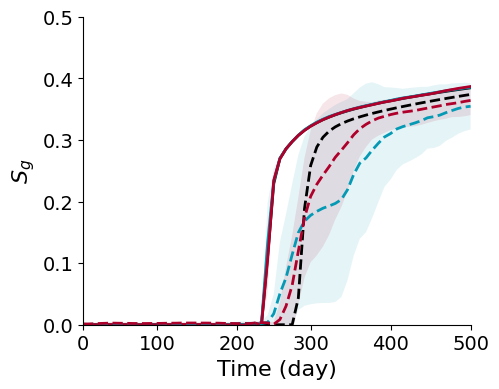

In [94]:
plt.figure(figsize=(5, 4))
colors = ['#0499b4', '#ae002a']
# ---------probed point-----------
plt.plot(range(64), sparse1_ref, color='k', linewidth=2)

plt.plot(range(64), sparse1_sat_mean, color=colors[0], linewidth=2)
plt.fill_between(range(64), sparse1_sat_mean - sparse1_sat_std, sparse1_sat_mean + sparse1_sat_std, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all1_sat_mean, color=colors[1], linewidth=2)
plt.fill_between(range(64), sparse_all1_sat_mean - sparse_all1_sat_std, sparse_all1_sat_mean + sparse_all1_sat_std, color=colors[1], alpha=0.1,edgecolor='none')

# ---------unprobed point-----------
plt.plot(range(64), sparse1_ref_unprob, color='k', linewidth=2, ls='--')

plt.plot(range(64), sparse1_sat_mean_unprob, color=colors[0], linewidth=2, ls='--')
plt.fill_between(range(64), sparse1_sat_mean_unprob - sparse1_sat_std_unprob, sparse1_sat_mean_unprob + sparse1_sat_std_unprob, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all1_sat_mean_unprob, color=colors[1], linewidth=2, ls='--')
plt.fill_between(range(64), sparse_all1_sat_mean_unprob - sparse_all1_sat_std_unprob, sparse_all1_sat_mean_unprob + sparse_all1_sat_std_unprob, color=colors[1], alpha=0.1, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])

yticks = np.arange(0, 0.51, 0.1)
plt.yticks(ticks=yticks)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('$S_g$', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.xlim(0, 63)
plt.ylim(bottom=0)
plt.savefig('conditional_outputs/figs_cart_sparse/Line_Cart_sparse1.pdf', bbox_inches='tight')
plt.show()

In [95]:
qt = (10, 10)
sparse5_sat = query_well_data(sparse5, qt, 1)
sparse_all5_sat = query_well_data(sparse_all5, qt, 1)
sparse5_ref = query_well_data(ref, qt, 1)
sparse5_sat_mean = np.mean(sparse5_sat, axis=0)
sparse_all5_sat_mean = np.mean(sparse_all5_sat, axis=0)
sparse5_sat_std = np.std(sparse5_sat, axis=0)
sparse_all5_sat_std = np.std(sparse_all5_sat, axis=0)

qt = (15, 15)
sparse5_sat_unprob = query_well_data(sparse5, qt, 1)
sparse_all5_sat_unprob = query_well_data(sparse_all5, qt, 1)
sparse5_ref_unprob = query_well_data(ref, qt, 1)
sparse5_sat_mean_unprob = np.mean(sparse5_sat_unprob, axis=0)
sparse_all5_sat_mean_unprob = np.mean(sparse_all5_sat_unprob, axis=0)
sparse5_sat_std_unprob = np.std(sparse5_sat_unprob, axis=0)
sparse_all5_sat_std_unprob = np.std(sparse_all5_sat_unprob, axis=0)

Querying generated data
Querying generated data
Querying reference data
Querying generated data
Querying generated data
Querying reference data


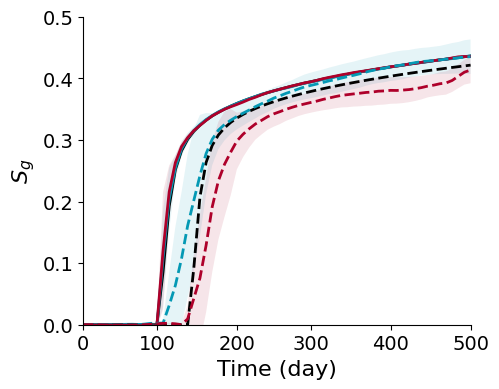

In [97]:
plt.figure(figsize=(5, 4))

# ---------probed point-----------
plt.plot(range(64), sparse5_ref, color='k', linewidth=2)

plt.plot(range(64), sparse5_sat_mean, color=colors[0], linewidth=2)
plt.fill_between(range(64), sparse5_sat_mean - sparse5_sat_std, sparse5_sat_mean + sparse5_sat_std, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all5_sat_mean, color=colors[1], linewidth=2)
plt.fill_between(range(64), sparse_all5_sat_mean - sparse_all5_sat_std, sparse_all5_sat_mean + sparse_all5_sat_std, color=colors[1], alpha=0.1,edgecolor='none')

# ---------unprobed point-----------
plt.plot(range(64), sparse5_ref_unprob, color='k', linewidth=2, ls='--')

plt.plot(range(64), sparse5_sat_mean_unprob, color=colors[0], linewidth=2, ls='--')
plt.fill_between(range(64), sparse5_sat_mean_unprob - sparse5_sat_std_unprob, sparse5_sat_mean_unprob + sparse5_sat_std_unprob, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all5_sat_mean_unprob, color=colors[1], linewidth=2, ls='--')
plt.fill_between(range(64), sparse_all5_sat_mean_unprob - sparse_all5_sat_std_unprob, sparse_all5_sat_mean_unprob + sparse_all5_sat_std_unprob, color=colors[1], alpha=0.1, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])

yticks = np.arange(0, 0.51, 0.1)
plt.yticks(ticks=yticks)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('$S_g$', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.xlim(0, 63)
plt.ylim(bottom=0)
plt.savefig('conditional_outputs/figs_cart_sparse/Line_Cart_sparse5.pdf', bbox_inches='tight')
plt.show()

In [98]:
pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
print(pts)
qt = pts[1]
print(qt)
sparse20_sat = query_well_data(sparse20, qt, 1)
sparse_all20_sat = query_well_data(sparse_all20, qt, 1)
sparse20_ref = query_well_data(ref, qt, 1)
sparse20_sat_mean = np.mean(sparse20_sat, axis=0)
sparse_all20_sat_mean = np.mean(sparse_all20_sat, axis=0)
sparse20_sat_std = np.std(sparse20_sat, axis=0)
sparse_all20_sat_std = np.std(sparse_all20_sat, axis=0)

qt = (11, 9)
sparse20_sat_unprob = query_well_data(sparse20, qt, 1)
sparse_all20_sat_unprob = query_well_data(sparse_all20, qt, 1)
sparse20_ref_unprob = query_well_data(ref, qt, 1)
sparse20_sat_mean_unprob = np.mean(sparse20_sat_unprob, axis=0)
sparse_all20_sat_mean_unprob = np.mean(sparse_all20_sat_unprob, axis=0)
sparse20_sat_std_unprob = np.std(sparse20_sat_unprob, axis=0)
sparse_all20_sat_std_unprob = np.std(sparse_all20_sat_unprob, axis=0)

[[41  1]
 [ 6  4]
 [15 53]
 [44 57]
 [31 33]
 [36 50]
 [10 35]
 [26 18]
 [23 62]
 [47 38]
 [51  8]
 [37  9]
 [57 24]
 [ 1 43]
 [21 19]
 [16 25]
 [55 46]
 [61 49]
 [ 5 14]
 [33 29]]
[6 4]
Querying generated data
Querying generated data
Querying reference data
Querying generated data
Querying generated data
Querying reference data


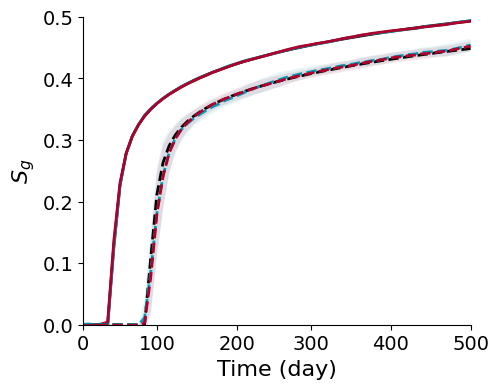

In [145]:
plt.figure(figsize=(5, 4))

# ---------probed point-----------
plt.plot(range(64), sparse20_ref, color='k', linewidth=2)

plt.plot(range(64), sparse20_sat_mean, color=colors[0], linewidth=2)
plt.fill_between(range(64), sparse20_sat_mean - sparse20_sat_std, sparse20_sat_mean + sparse20_sat_std, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all20_sat_mean, color=colors[1], linewidth=2)
plt.fill_between(range(64), sparse_all20_sat_mean - sparse_all20_sat_std, sparse_all20_sat_mean + sparse_all20_sat_std, color=colors[1], alpha=0.1,edgecolor='none')

# ---------unprobed point-----------
plt.plot(range(64), sparse20_ref_unprob, color='k', linewidth=2, ls='--')

plt.plot(range(64), sparse20_sat_mean_unprob, color=colors[0], linewidth=2, ls='--')
plt.fill_between(range(64), sparse20_sat_mean_unprob - sparse20_sat_std_unprob, sparse20_sat_mean_unprob + sparse20_sat_std_unprob, color=colors[0], alpha=0.1, edgecolor='none')

plt.plot(range(64), sparse_all20_sat_mean_unprob, color=colors[1], linewidth=2, ls='--')
plt.fill_between(range(64), sparse_all20_sat_mean_unprob - sparse_all20_sat_std_unprob, sparse_all20_sat_mean_unprob + sparse_all20_sat_std_unprob, color=colors[1], alpha=0.1, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])

yticks = np.arange(0, 0.51, 0.1)
plt.ylim(0, 0.5)
plt.yticks(ticks=yticks)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('$S_g$', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.xlim(0, 63)
plt.ylim(bottom=0)
plt.savefig('conditional_outputs/figs_cart_sparse/Line_Cart_sparse20.pdf', bbox_inches='tight')
plt.show()

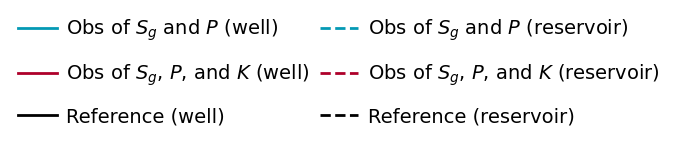

In [108]:
from matplotlib.lines import Line2D
legend_elements = [
    Line2D([0], [0], color=colors[0], lw=2, ls='-', label='Obs of $S_g$ and $P$ (well)'),
    Line2D([0], [0], color=colors[1], lw=2, ls='-', label='Obs of $S_g$, $P$, and $K$ (well)'),
    Line2D([0], [0], color='k', lw=2, ls='-', label='Reference (well)'),
    Line2D([0], [0], color=colors[0], lw=2, ls='--', label='Obs of $S_g$ and $P$ (reservoir)'),
    Line2D([0], [0], color=colors[1], lw=2, ls='--', label='Obs of $S_g$, $P$, and $K$ (reservoir)'),
    Line2D([0], [0], color='k', lw=2, ls='--', label='Reference (reservoir)')
]

fig, ax = plt.subplots(figsize=(6, 1))
ax.axis('off')

fig.legend(
    handles=legend_elements,
    loc='center',
    ncol=2,
    frameon=False,
    handlelength=2,
    handletextpad=0.5,
    columnspacing=0.5,
    labelspacing=1,
    fontsize=14,
)

# plt.tight_layout()
plt.savefig('conditional_outputs/figs_cart_sparse/Line_legend.pdf', bbox_inches='tight')
plt.show()

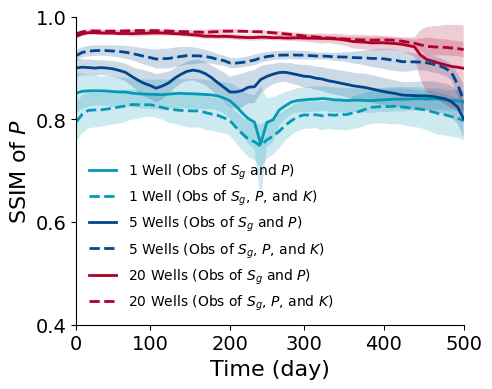

In [8]:
from skimage.metrics import structural_similarity as ssim
def compute_temporal_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref[t, :, :, 0], gen[i, t, :, :, 0], data_range=gen[i, t, :, :, 0].max() - gen[i, t, :, :, 0].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)


sp1_ssim = compute_temporal_ssim(ref, sparse1)
sp5_ssim = compute_temporal_ssim(ref, sparse5)
sp20_ssim = compute_temporal_ssim(ref, sparse20)
sp_all1_ssim = compute_temporal_ssim(ref, sparse_all1)
sp_all5_ssim = compute_temporal_ssim(ref, sparse_all5)
sp_all20_ssim = compute_temporal_ssim(ref, sparse_all20)


def plot_func(arr, c, ls, label):
    mean = np.mean(arr, axis=0)
    std = np.std(arr, axis=0)
    plt.plot(range(64), mean, color=c, linewidth=2, ls=ls, label=label)
    plt.fill_between(range(64), mean - std, mean + std, color=c, alpha=0.2, edgecolor='none')


plt.figure(figsize=(5, 4))
colors = ['#0499b4', '#00468c', '#ae002a']
plot_func(sp1_ssim, colors[0], '-', r'1 Well (Obs of $S_g$ and $P$)')
plot_func(sp_all1_ssim, colors[0], '--', r'1 Well (Obs of $S_g$, $P$, and $K$)')
plot_func(sp5_ssim, colors[1], '-', r'5 Wells (Obs of $S_g$ and $P$)')
plot_func(sp_all5_ssim, colors[1], '--', r'5 Wells (Obs of $S_g$, $P$, and $K$)')
plot_func(sp20_ssim, colors[2], '-', r'20 Wells (Obs of $S_g$ and $P$)')
plot_func(sp_all20_ssim, colors[2], '--', r'20 Wells (Obs of $S_g$, $P$, and $K$)')


labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.4, 1.0)
plt.yticks([0.4, 0.6, 0.8, 1.0])
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('SSIM of $P$', fontsize=16)
plt.legend(fontsize=10, frameon=False, loc='lower left')
plt.xlim(0, 63)
plt.ylim(top=1)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('conditional_outputs/figs_cart_sparse/SSIM_Cart_SR_P.pdf', bbox_inches='tight')
plt.show()

**Spatial variation of K**

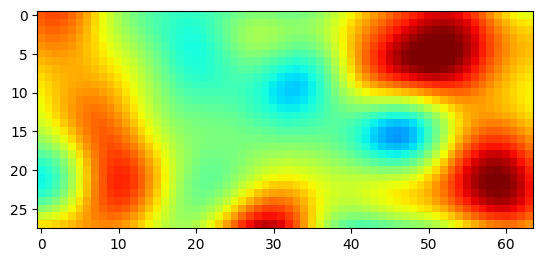

In [355]:
plt.imshow(ref[0, :28, :, -1],cmap='jet', vmin=1.5, vmax=6.5)

In [109]:
sparse1_k_line = sparse1_k[:, 32, :]
sparse_all1_k_line = sparse_all1_k[:, 32, :]
ref1_k_line = ref[0, 32, :, -1]

sparse5_k_line = sparse5_k[:, 28, :]
sparse_all5_k_line = sparse_all5_k[:, 28, :]
ref5_k_line = ref[0, 28, :, -1]

sparse20_k_line = sparse20_k[:, 37, :]
sparse_all20_k_line = sparse_all20_k[:, 37, :]
ref20_k_line = ref[1, 37, :, -1]

In [110]:
def compute_mean_std(data):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    return mean, std
def plot_line_and_fill(data, color):
    mean, std = compute_mean_std(data)
    plt.plot(range(64), mean, color=color, linewidth=2, ls='--')
    plt.fill_between(range(64), mean - std, mean + std, color=color, alpha=0.1, edgecolor='none')

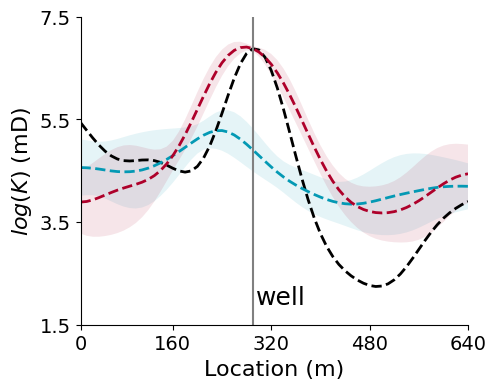

In [123]:
plt.figure(figsize=(5, 4))
plt.plot(range(64), ref1_k_line, color='k', linewidth=2, ls='--')

plot_line_and_fill(sparse1_k_line, colors[0])
plot_line_and_fill(sparse_all1_k_line, colors[1])
plt.axvline(28, color='gray', linestyle='-', linewidth=1.5)
plt.text(28 + 0.5, 1.8, 'well', color='k', fontsize=18, ha='left', va='bottom')
# plt.scatter(28, ref1_k_line[28], color='green', marker='o', s=50, zorder=101)

plt.xlim(0, 63)
plt.ylim(1.5, 7.5)
plt.yticks([1.5, 3.5, 5.5, 7.5])
phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.savefig('conditional_outputs/figs_cart_sparse/Line_spatial_K1.pdf', bbox_inches='tight')
plt.show()

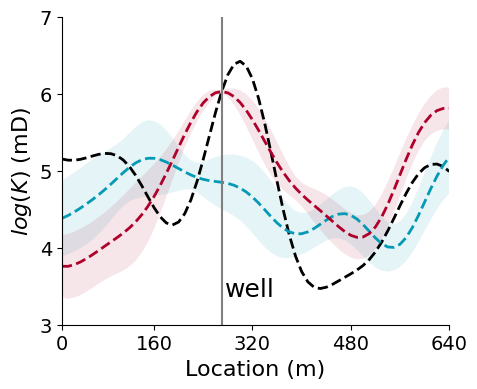

In [133]:
plt.figure(figsize=(5, 4))
plt.plot(range(64), ref5_k_line, color='k', linewidth=2, ls='--')
plot_line_and_fill(sparse5_k_line, colors[0])
plot_line_and_fill(sparse_all5_k_line, colors[1])
plt.axvline(26, color='gray', linestyle='-', linewidth=1.5)
plt.text(26 + 0.5, 3.3, 'well', color='k', fontsize=18, ha='left', va='bottom')

plt.xlim(0, 63)
plt.ylim(3, 7)
plt.yticks([3, 4, 5, 6, 7])
phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/figs_cart_sparse/Line_spatial_K5.pdf', bbox_inches='tight')
plt.show()

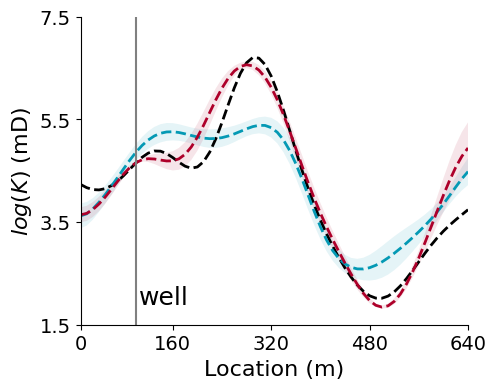

In [139]:
plt.figure(figsize=(5, 4))
plt.plot(range(64), ref20_k_line, color='k', linewidth=2, ls='--')
plot_line_and_fill(sparse20_k_line, colors[0])
plot_line_and_fill(sparse_all20_k_line, colors[1])
plt.axvline(9, color='gray', linestyle='-', linewidth=1.5)
plt.text(9 + 0.5, 1.8, 'well', color='k', fontsize=18, ha='left', va='bottom')

plt.xlim(0, 63)
plt.ylim(1.5, 7.5)
plt.yticks([1.5, 3.5, 5.5, 7.5])
phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/figs_cart_sparse/Line_spatial_K20.pdf', bbox_inches='tight')
plt.show()

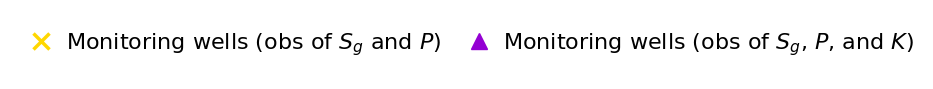

In [39]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([0], [0], marker='x', color='gold', label='Monitoring wells (obs of $S_g$ and $P$)',
           markerfacecolor='blue', markersize=12, markeredgewidth=2.5, linestyle='None'),
    Line2D([0], [0], color='darkviolet', marker='^', label='Monitoring wells (obs of $S_g$, $P$, and $K$)',
           markersize=12, linestyle='None')
]

fig, ax = plt.subplots(figsize=(7, 1))
ax.legend(handles=legend_elements, loc='center', frameon=False, fontsize=16, ncol=2, handletextpad=0.1, columnspacing=0.7, labelspacing=0,)
ax.axis('off')
plt.tight_layout()
plt.savefig('conditional_outputs/figs_cart_sparse/Legends_well.pdf', bbox_inches='tight', pad_inches=0.0)
plt.show()

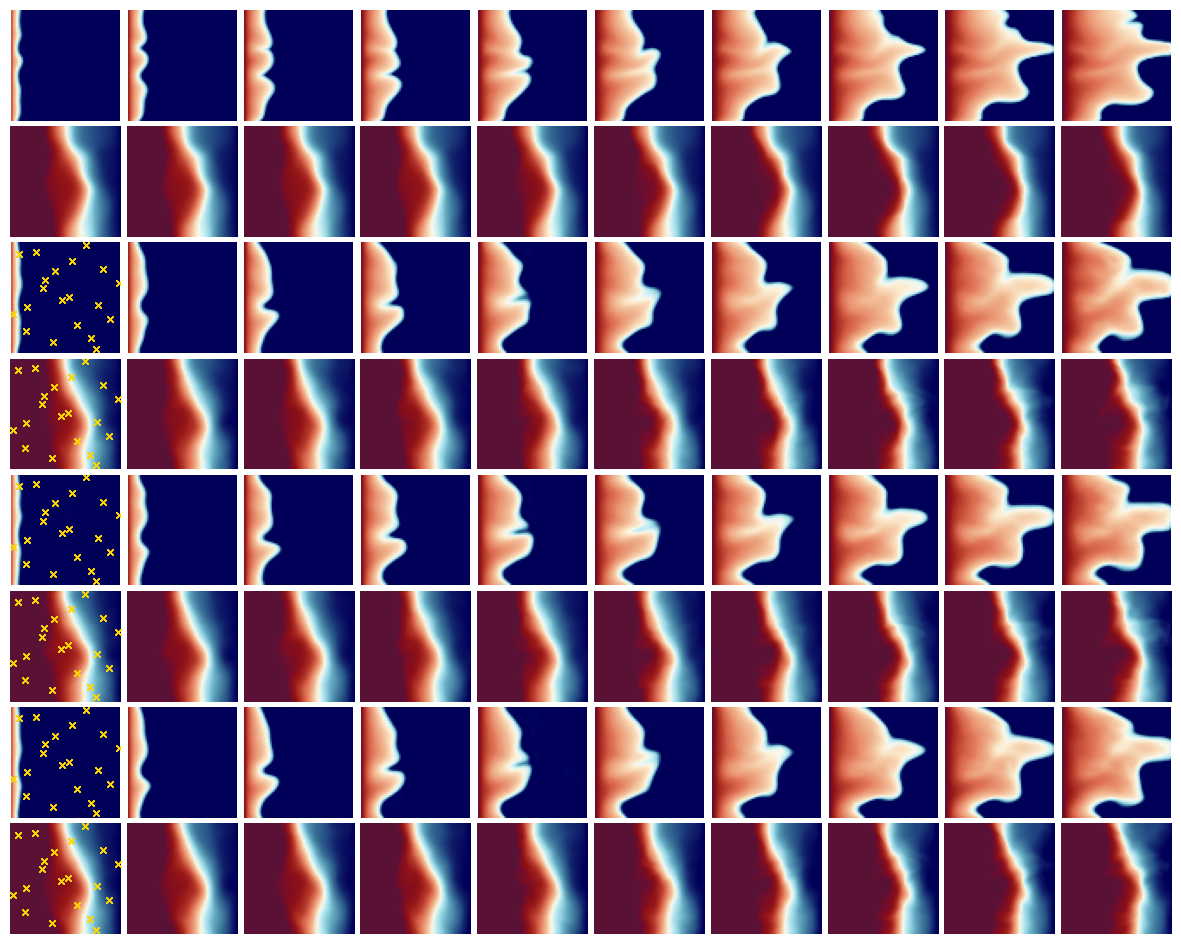

In [10]:
sr_16_sg = sparse_all20[..., 1]
sr_16_p = sparse_all20[..., 0]

days = [50, 100, 150, 200, 250, 300, 350, 400, 450, 500]
ts = [int((d / (500 / 64))) for d in days]
ts[-1] = 63

pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')

fig, ax = plt.subplots(8, 10, figsize=(15, 12))
for i in range(10):
    t = ts[i]
    
    ax[0, i].imshow(ref[t, :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[1, i].imshow(ref[t, ..., 0], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[2, i].imshow(sr_16_sg[0, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[3, i].imshow(sr_16_p[0, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[4, i].imshow(sr_16_sg[3, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[5, i].imshow(sr_16_p[3, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)
    
    ax[6, i].imshow(sr_16_sg[6, t, :, :-1], cmap=mycmap, vmin=0, vmax=0.6)
    ax[7, i].imshow(sr_16_p[6, t, ...], cmap=mycmap, vmin=12e6, vmax=15e6)

for row in range(8):
    for col in range(10):
        ax[row, col].axis('off')
        if row > 1:
            for y, x in pts:
                ax[row, 0].scatter(x, y, color='gold', marker='x', s=20, linewidths=0.7)



plt.subplots_adjust(wspace=0.05, hspace=0.05)
# plt.tight_layout()
plt.savefig('conditional_outputs/more_results/SM.pdf', bbox_inches='tight')

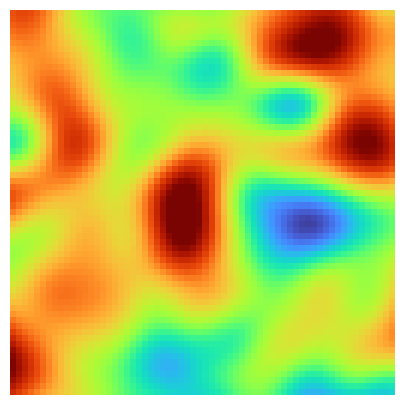

In [16]:
plt.figure(figsize=(5, 5))
plt.imshow(ref[0, :, :, -1], cmap='turbo', vmin=1.5, vmax=6.5)
plt.axis('off')
# plt.axhline(y=32, color='k', linestyle='-.', linewidth=4.5)
plt.savefig('conditional_outputs/more_results/SM_ref_K.pdf', bbox_inches='tight')

Sparse_all20 K shape: (10, 64, 64)


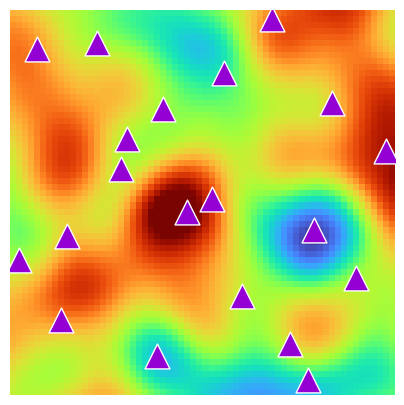

In [17]:
sparse_all20_k = np.mean(sparse_all20[..., -1], axis=1)
print(f"Sparse_all20 K shape: {sparse_all20_k.shape}")
query_pts = np.load('conditional_outputs/npys/query_pts_cart_sparse20.npy')
plt.figure(figsize=(5, 5))
plt.imshow(sparse_all20_k[6, :, :], cmap='turbo', vmin=1.5, vmax=6.5)
for y, x in query_pts:
        plt.scatter(x, y, color='darkviolet', marker='^', s=320, edgecolors='white')
plt.axis('off')
plt.savefig('conditional_outputs/more_results/SM_K3.pdf', bbox_inches='tight')

# **Inpainting**
## - damaged saturation
## - damaged permeability

In [3]:
operator =  get_operator(name='cartesian_inpainting_v2',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1990,
                        damage_size=32,
                        state_variable='saturation',
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

Simulation data loaded, with shape (64, 64, 64, 3)


In [ ]:
no_of_samples = 10
time_length = 64
latent_size = 256

x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
measurement_ref = operator.sparse_cartesian_measurement()
samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

In [5]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")

Generated latents shape: torch.Size([10, 64, 256])


In [6]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [7]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Inpainting_sat.pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


In [8]:
ref = operator.retrieve_data()['simdata']
print(f"Reference simdata shape: {ref.shape}")
inpainting_sat_ref = operator.retrieve_data()['measurement']
print(f"Inpainting reference saturation shape: {inpainting_sat_ref.shape}")
inpainting_gene = torch.load('conditional_outputs/pts/CNF_out_Inpainting_sat.pt').cpu().numpy()
print(f"Inpainting generated saturation shape: {inpainting_gene.shape}")
mask = operator.retrieve_data()['mask']
print(f"Inpainting mask shape: {mask.shape}")

Reference simdata shape: (64, 64, 64, 3)
Inpainting reference saturation shape: (64, 64, 64)
Inpainting generated saturation shape: (10, 64, 64, 64, 3)
Inpainting mask shape: (64, 64)


1.0 0.0


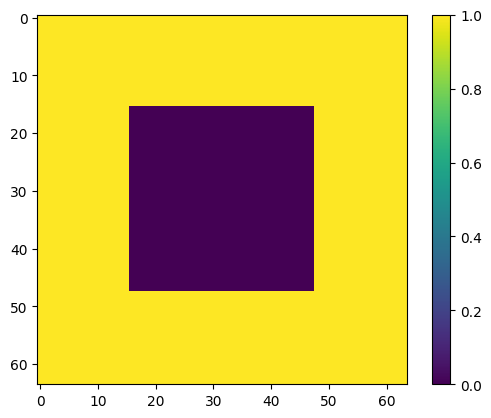

In [9]:
print(mask[0, 0], mask[32, 32])
plt.imshow(mask)
plt.colorbar()

In [10]:
def mask_out(data, filter):
    data = data.copy()
    data[filter == 0] = np.nan
    return data

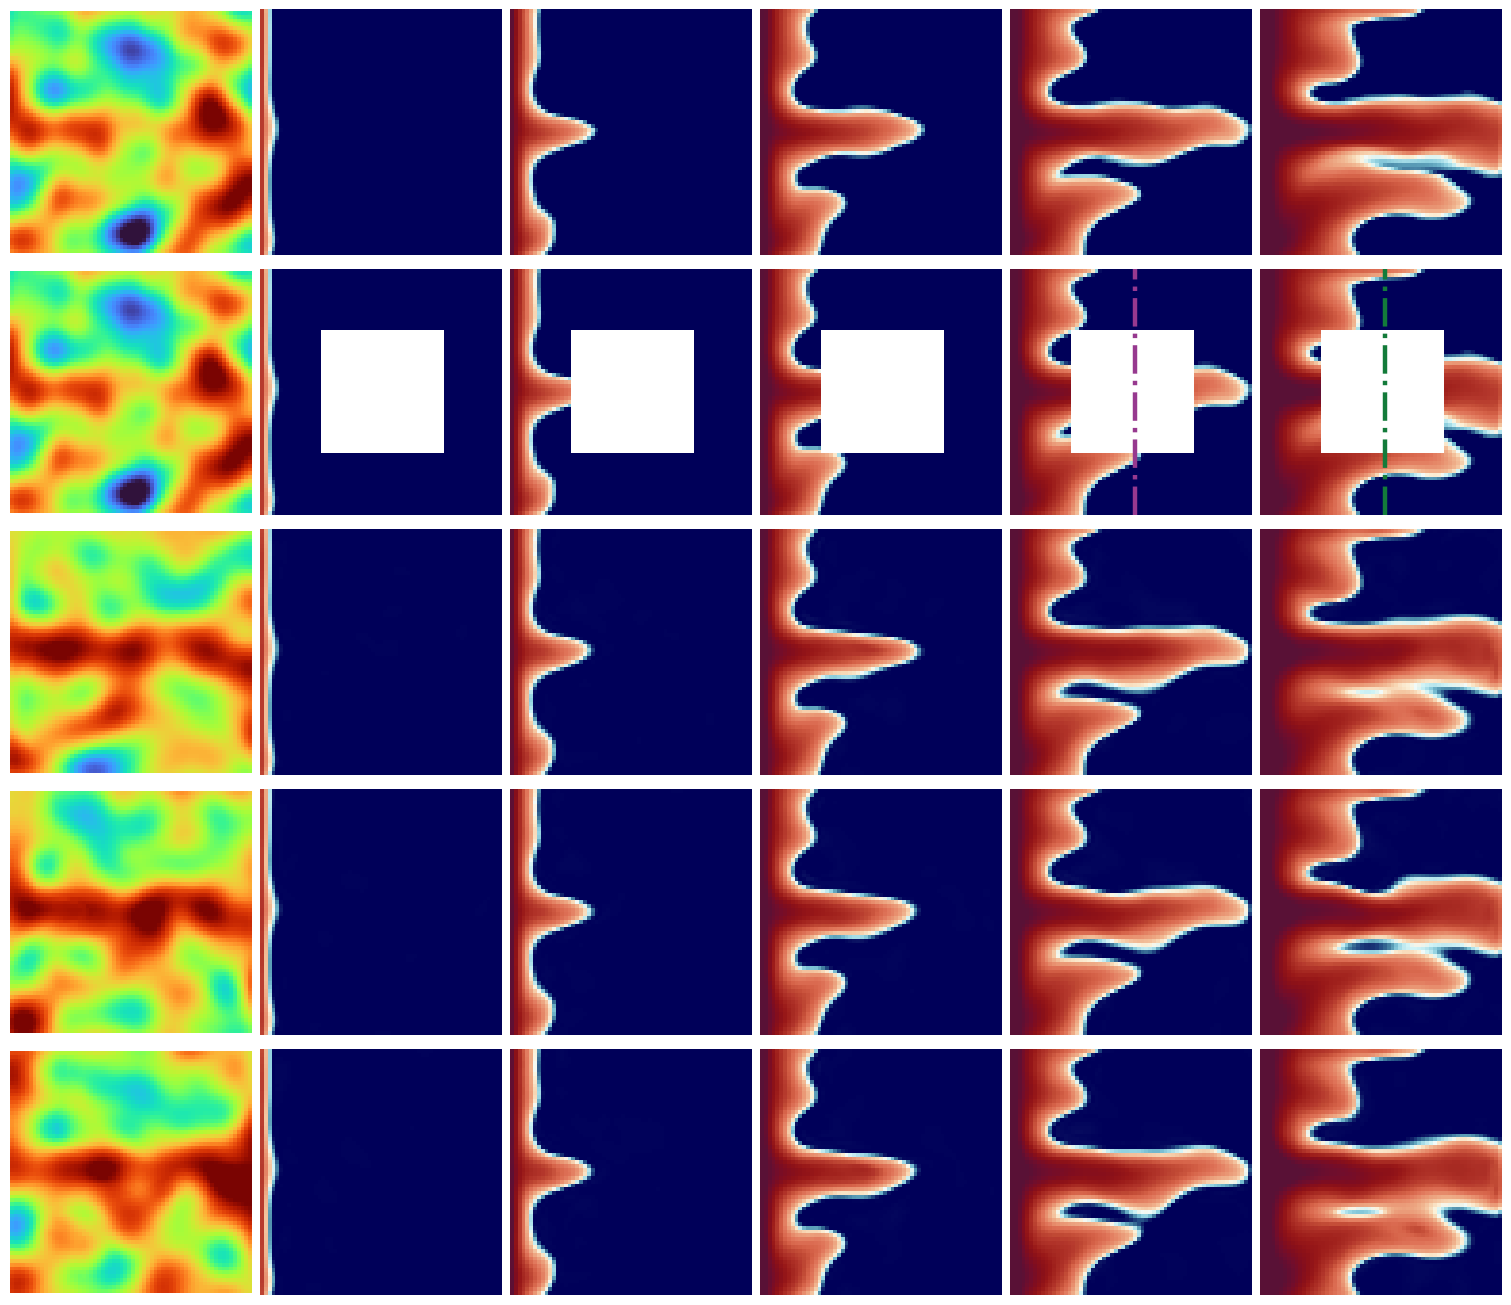

In [11]:
def plot_inpainting_results(generation, label, conditions, mask):
    """
    generation: <N, t, h, w, c>
    label: <t, h, w, c>
    conditions: <t, h, w>
    mask: <h, w>
    """
    ts = [3, 12, 25, 38, 63]
    platteo = ['#97398f', '#137b3a', '#b7b718']
    
    fig, ax = plt.subplots(5, 6, figsize=(15, 13), layout='constrained')
    for i in range(5):
        for j in range(6):
            ax[i, j].axis('off')
    
    # --- reference ---
    ax[0, 0].imshow(label[0, ..., -1], cmap='turbo', vmin=1.5, vmax=6.5)
    for j in range(1, 6):
        ax[0, j].imshow(label[ts[j-1], :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.5)
    
    # --- conditions ---
    ax[1, 0].imshow(label[0, ..., -1], cmap='turbo', vmin=1.5, vmax=6.5)
    for j in range(1, 6):
        ax[1, j].imshow(mask_out(conditions[ts[j-1]], mask)[:, :-1], cmap=mycmap, vmin=0, vmax=0.5)
        if j >= 4:
            ax[1, j].axvline(32, color=platteo[j-4], linestyle='-.', linewidth=3.2)
    
    # --- generated ---
    for i in range(2, 5):
        ax[i, 0].imshow(generation[i*2, ts[i-2], ..., -1], cmap='turbo', vmin=1.5, vmax=6.5)
        for j in range(1, 6):
            ax[i, j].imshow(generation[i*2, ts[j-1], :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.5)
    plt.show()
    return fig

fig = plot_inpainting_results(inpainting_gene, ref, inpainting_sat_ref, mask)
# fig.savefig('conditional_outputs/inpainting/Inpainting_sat.pdf', bbox_inches='tight')
    

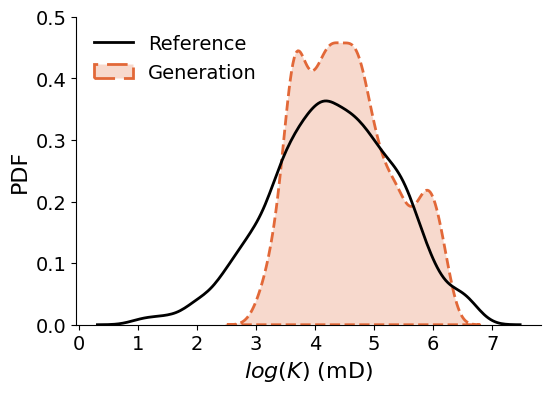

In [85]:
k_ref = ref[0, ..., -1]
k_gene_ensemble = np.mean(inpainting_gene[:, :, ..., -1], axis=(0, 1))

plt.figure(figsize=(6, 4))

import seaborn as sns
sns.kdeplot(k_ref.flatten(), color='black', label='Reference', linewidth=2, fill=False, ls='-')
sns.kdeplot(k_gene_ensemble.flatten(), color='#e26838', label='Generation', linewidth=2, fill=True, ls='--')
# plt.xlim(1.5, 6.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 0.5)
plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
plt.xlabel('$log(K)$ (mD)', fontsize=16)
plt.ylabel('PDF', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(fontsize=14, frameon=False, loc='upper left')
plt.savefig('conditional_outputs/inpainting/Inpainting_sat_K.pdf', bbox_inches='tight')
plt.show()

In [86]:
def plot_sat_mean_std(t, color, name):
    sat = inpainting_gene[:, t, :, 32, 1]
    sat_mean = np.mean(sat, axis=0)
    sat_std = np.std(sat, axis=0)
    plt.plot(range(64), sat_mean, color=color, linewidth=2, label=name, ls='--')
    plt.fill_between(range(64), sat_mean - sat_std, sat_mean + sat_std, color=color, alpha=0.2, edgecolor='none')

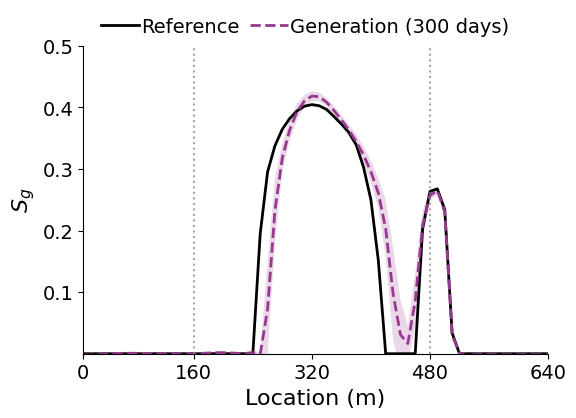

In [88]:
plt.figure(figsize=(6, 4))
plt.plot(range(64), ref[38, :, 32, 1], color='k', linewidth=2, ls='-', label='Reference')
plot_sat_mean_std(38, '#97398f', 'Generation (300 days)')
plt.axvline(15, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axvline(47, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.xlim(0, 63)
plt.ylim(0, 0.5)
plt.yticks([0.1, 0.2, 0.3, 0.4, 0.5])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$S_g$', fontsize=16)
plt.legend(fontsize=14, loc='upper left', frameon=False, ncol=2, handletextpad=0.1, columnspacing=0.5, labelspacing=0.5, bbox_to_anchor=(-0.00, 1.15))
plt.savefig('conditional_outputs/inpainting/Inpainting_sat_line300.pdf', bbox_inches='tight')
plt.show()

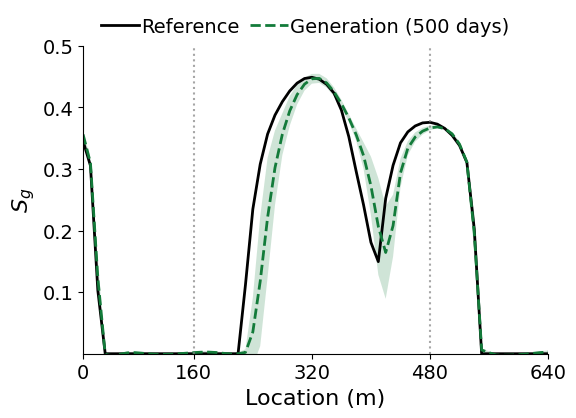

In [89]:
plt.figure(figsize=(6, 4))
plt.plot(range(64), ref[-1, :, 32, 1], color='k', linewidth=2, ls='-', label='Reference')
plot_sat_mean_std(-1, '#137b3a', 'Generation (500 days)')
plt.axvline(15, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axvline(47, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.xlim(0, 63)
plt.ylim(0, 0.5)
plt.yticks([0.1, 0.2, 0.3, 0.4, 0.5])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$S_g$', fontsize=16)
plt.legend(fontsize=14, loc='upper left', frameon=False, ncol=2, handletextpad=0.1, columnspacing=0.5, labelspacing=0.5, bbox_to_anchor=(-0.00, 1.15))
plt.savefig('conditional_outputs/inpainting/Inpainting_sat_line500.pdf', bbox_inches='tight')
plt.show()

SSIM shape: (10, 64)


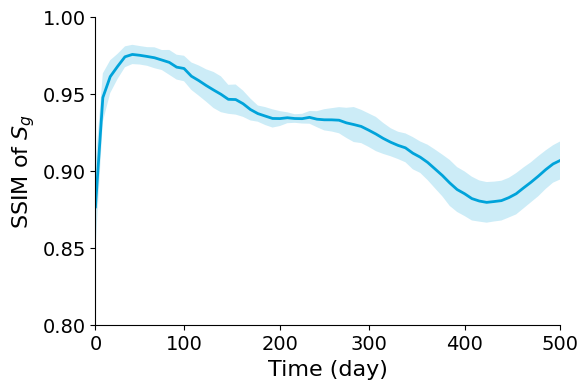

In [90]:
from skimage.metrics import structural_similarity as ssim

def compute_temporal_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref[t, :, :, 1], gen[i, t, :, :, 1], data_range=ref[t, :, :, 1].max() - ref[t, :, :, 1].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)

gene_ssim = compute_temporal_ssim(ref, inpainting_gene)
print(f"SSIM shape: {gene_ssim.shape}")

plt.figure(figsize=(6, 4))
plt.plot(range(64), np.mean(gene_ssim, axis=0), color='#00a3da', linewidth=2, label='SSIM')
plt.fill_between(range(64), np.mean(gene_ssim, axis=0) - np.std(gene_ssim, axis=0), 
                 np.mean(gene_ssim, axis=0) + np.std(gene_ssim, axis=0), color='#00a3da', alpha=0.2, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.8, 1.0)
plt.yticks([0.8, 0.85, 0.9, 0.95, 1.0])
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('SSIM of $S_g$', fontsize=16)
plt.xlim(0, 63)
plt.ylim(top=1)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/inpainting/Inpainting_sat_ssim_sg.pdf', bbox_inches='tight')
plt.show()

*Permeability damage*

In [91]:
operator =  get_operator(name='cartesian_inpainting',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1990,
                        damage_size=32,
                        state_variable='permeability',
                        )
noiser = get_noise(sigma=0.0, name='gaussian')

cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-3)    # 1e-2
measurement_cond_fn = partial(cond_method.conditioning)

sampler = create_sampler(sampler='ddpm',
                         steps=1000,
                         noise_schedule="cosine",
                         model_mean_type="epsilon",
                         model_var_type="learned_range",
                         dynamic_threshold=False,
                         clip_denoised=True,
                         rescale_timesteps=False,
                         timestep_respacing="")

sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)

no_of_samples = 10
time_length = 64
latent_size = 256

# x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
# measurement_ref = operator.sparse_cartesian_measurement()
# samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]

Simulation data loaded, with shape (64, 64, 64, 3)


In [53]:
gen_latents = torch.cat(samples)
gen_latents = operator._unnorm(gen_latents)
gen_latents = gen_latents[:,0]
print(f"Generated latents shape: {gen_latents.shape}")

Generated latents shape: torch.Size([10, 64, 256])


In [54]:
from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                in_coord_features=2,
                                in_latent_features=256,
                                out_features=3,
                                num_hidden_layers=5,
                                hidden_features=128)
ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
nf.load_state_dict(ckpt['model_state_dict'])
nf.eval()
nf.to(device)
del ckpt
print('nf loaded')

nf loaded


In [55]:
whole_coords = operator._gene_cartesian_coord()
whole_coords_in = whole_coords.unsqueeze(0).to(device)
gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
gen_latents_in = gen_latents_in.to(device)
with torch.no_grad():
    nf_out_gene = nf(whole_coords_in, gen_latents_in)
nf_out_gene = operator._unnorm_cnf(nf_out_gene)
nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
print(f"CNF output shape: {nf_out_gene.shape}")
# torch.save(nf_out_gene, 'conditional_outputs/pts/CNF_out_Inpainting_perm.pt')

CNF output shape: torch.Size([10, 64, 64, 64, 3])


In [92]:
ref = operator.retrieve_data()['simdata']
print(f"Reference simdata shape: {ref.shape}")

inpainting_sat_ref = operator.retrieve_data()['measurement']
print(f"Inpainting reference saturation shape: {inpainting_sat_ref.shape}")

inpainting_gene = torch.load('conditional_outputs/pts/CNF_out_Inpainting_perm.pt').cpu().numpy()
# inpainting_gene = nf_out_gene.detach().cpu().numpy()
print(f"Inpainting generated saturation shape: {inpainting_gene.shape}")

mask = operator.retrieve_data()['mask']
print(f"Inpainting mask shape: {mask.shape}")

Reference simdata shape: (64, 64, 64, 3)
Inpainting reference saturation shape: (64, 64, 64)
Inpainting generated saturation shape: (10, 64, 64, 64, 3)
Inpainting mask shape: (64, 64)


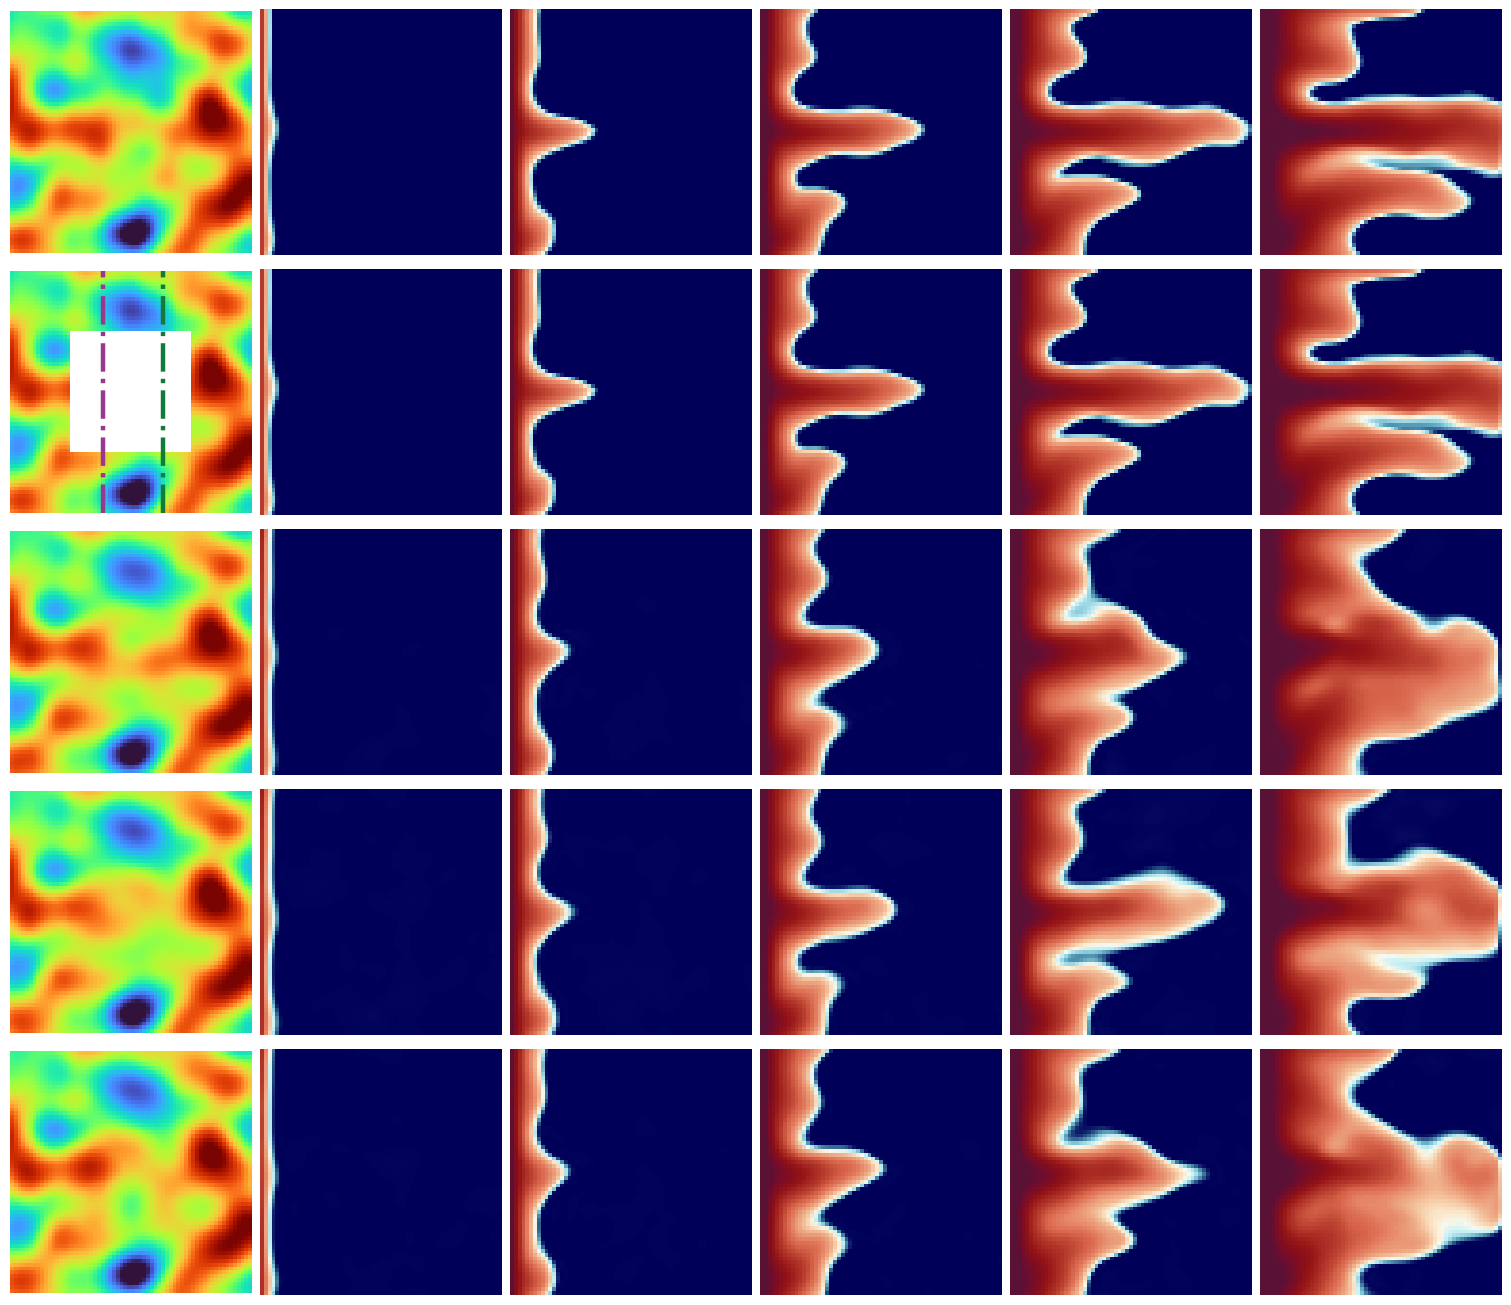

In [62]:
def plot_inpainting_results_perm(generation, label, conditions, mask):
    """
    generation: <N, t, h, w, c>
    label: <t, h, w, c>
    conditions: <t, h, w>
    mask: <h, w>
    """
    ts = [3, 12, 25, 38, 63]
    platteo = ['#97398f', '#137b3a']
    
    fig, ax = plt.subplots(5, 6, figsize=(15, 13), layout='constrained')
    for i in range(5):
        for j in range(6):
            ax[i, j].axis('off')
    
    # --- reference ---
    ax[0, 0].imshow(label[0, ..., -1], cmap='turbo', vmin=1.5, vmax=6.5)
    
    for j in range(1, 6):
        ax[0, j].imshow(label[ts[j-1], :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.5)
    
    # --- conditions ---
    ax[1, 0].imshow(mask_out(label[0, ..., -1], mask), cmap='turbo', vmin=1.5, vmax=6.5)
    ax[1, 0].axvline(24, color=platteo[0], linestyle='-.', linewidth=3.2)
    ax[1, 0].axvline(40, color=platteo[1], linestyle='-.', linewidth=3.2)
    for j in range(1, 6):
        ax[1, j].imshow(label[ts[j-1], :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.5)
    
    # --- generated ---
    for i in range(2, 5):
        ax[i, 0].imshow(generation[i*1, ts[i-2], ..., -1], cmap='turbo', vmin=1.5, vmax=6.5)
        for j in range(1, 6):
            ax[i, j].imshow(generation[i*1, ts[j-1], :, :-1, 1], cmap=mycmap, vmin=0, vmax=0.5)
    plt.show()
    return fig

fig = plot_inpainting_results_perm(inpainting_gene, ref, inpainting_sat_ref, mask)
fig.savefig('conditional_outputs/inpainting/Inpainting_perm.pdf', bbox_inches='tight')

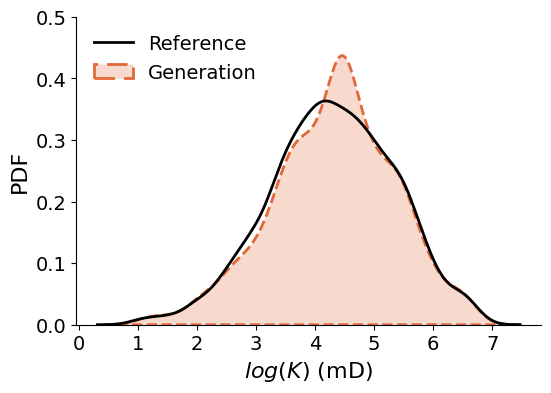

In [93]:
k_ref = ref[0, ..., -1]
k_gene_ensemble = np.mean(inpainting_gene[:, :, ..., -1], axis=(0, 1))
# k_miss = k_ref[mask != 0]
# print(k_miss.shape)

plt.figure(figsize=(6, 4))

import seaborn as sns
sns.kdeplot(k_ref.flatten(), color='black', label='Reference', linewidth=2, fill=False, ls='-')
sns.kdeplot(k_gene_ensemble.flatten(), color='#e26838', label='Generation', linewidth=2, fill=True, ls='--')
# sns.kdeplot(k_miss.flatten(), color='blue', label='Missing', linewidth=2, fill=True, ls='--')
# plt.xlim(1.5, 6.5)
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0, 0.5)
plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5])
plt.xlabel('$log(K)$ (mD)', fontsize=16)
plt.ylabel('PDF', fontsize=16)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.legend(fontsize=14, frameon=False, loc='upper left')
plt.savefig('conditional_outputs/inpainting/Inpainting_perm_K.pdf', bbox_inches='tight')
plt.show()

In [94]:
def plot_perm_mean_std(x, color, name):
    sat = np.mean(inpainting_gene[:, :, :, x, -1], axis=1)
    sat_mean = np.mean(sat, axis=0)
    sat_std = np.std(sat, axis=0)
    plt.plot(range(64), sat_mean, color=color, linewidth=2, label=name, ls='--')
    plt.fill_between(range(64), sat_mean - sat_std, sat_mean + sat_std, color=color, alpha=0.2, edgecolor='none')

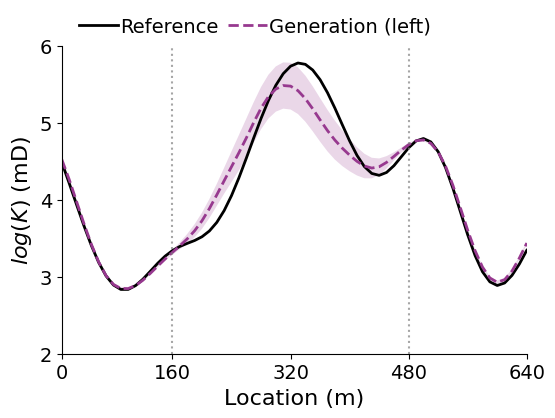

In [96]:
plt.figure(figsize=(6, 4))
plt.plot(range(64), ref[0, :, 24, -1], color='k', linewidth=2, ls='-', label='Reference')
plot_perm_mean_std(24, '#97398f', 'Generation (left)')
plt.axvline(15, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axvline(47, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.xlim(0, 63)
plt.ylim(2, 6)
plt.yticks([2, 3, 4, 5, 6])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)
plt.legend(fontsize=14, loc='upper left', frameon=False, ncol=2, handletextpad=0.1, columnspacing=0.5, labelspacing=0.5, bbox_to_anchor=(-0.00, 1.15))
plt.savefig('conditional_outputs/inpainting/Inpainting_perm_line_left.pdf', bbox_inches='tight')
plt.show()

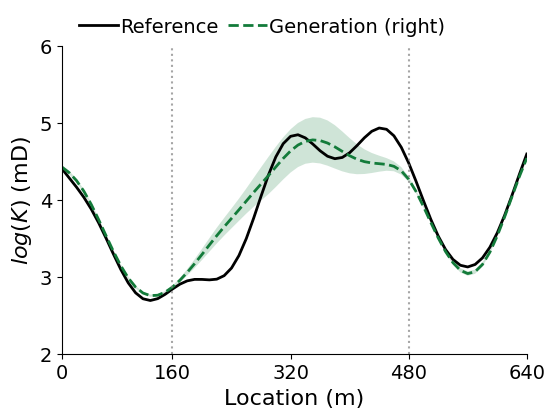

In [97]:
plt.figure(figsize=(6, 4))
plt.plot(range(64), ref[0, :, 40, -1], color='k', linewidth=2, ls='-', label='Reference')
plot_perm_mean_std(40, '#137b3a', 'Generation (right)')
plt.axvline(15, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
plt.axvline(47, color='gray', linestyle=':', linewidth=1.5, alpha=0.7)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
plt.xlim(0, 63)
plt.ylim(2, 6)
plt.yticks([2, 3, 4, 5, 6])

phys_labels = [0, 160, 320, 480, 640]
xticks = [int(x * 63 / 640) for x in phys_labels]
xtick_labels = [str(x) for x in phys_labels]
plt.xticks(ticks=xticks, labels=xtick_labels)

plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlabel('Location (m)', fontsize=16)
plt.ylabel('$log(K)$ (mD)', fontsize=16)
plt.legend(fontsize=14, loc='upper left', frameon=False, ncol=2, handletextpad=0.1, columnspacing=0.5, labelspacing=0.5, bbox_to_anchor=(-0.00, 1.15))
plt.savefig('conditional_outputs/inpainting/Inpainting_perm_line_right.pdf', bbox_inches='tight')
plt.show()

In [98]:
from skimage.metrics import structural_similarity as ssim

def compute_temporal_ssim(ref, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(ref[t, :, :, 1], gen[i, t, :, :, 1], data_range=ref[t, :, :, 1].max() - ref[t, :, :, 1].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)

gene_ssim = compute_temporal_ssim(ref, inpainting_gene)
print(f"SSIM shape: {gene_ssim.shape}")

SSIM shape: (10, 64)


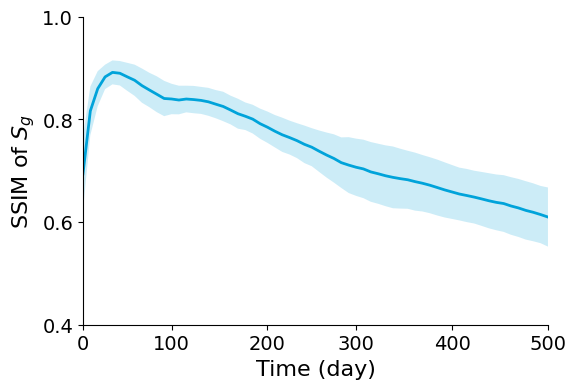

In [99]:
plt.figure(figsize=(6, 4))
plt.plot(range(64), np.mean(gene_ssim, axis=0), color='#00a3da', linewidth=2, label='SSIM')
plt.fill_between(range(64), np.mean(gene_ssim, axis=0) - np.std(gene_ssim, axis=0), 
                 np.mean(gene_ssim, axis=0) + np.std(gene_ssim, axis=0), color='#00a3da', alpha=0.2, edgecolor='none')

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.ylim(0.4, 1.0)
plt.yticks([0.4, 0.6, 0.8, 1.0])
plt.xlabel('Time (day)', fontsize=16)
plt.ylabel('SSIM of $S_g$', fontsize=16)
plt.xlim(0, 63)
plt.ylim(top=1)

ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/inpainting/Inpainting_perm_ssim_sg.pdf', bbox_inches='tight')
plt.show()

## **Sensitivity analysis**

In [12]:

well_1 = [(32, 32)]
well_4 = [(21, 21), (21, 42),
          (42, 21), (42, 42)]
well_9 = [(16, 16), (16, 32), (16, 48),
          (32, 16), (32, 32), (32, 48),
          (48, 16), (48, 32), (48, 48)]
well_16 = [(13, 13), (13, 26), (13, 39), (13, 52),
          (26, 13), (26, 26), (26, 39), (26, 52),
          (39, 13), (39, 26), (39, 39), (39, 52),
          (52, 13), (52, 26), (52, 39), (52, 52)]
well_25 = [(11, 11), (11, 22), (11, 33), (11, 44), (11, 55),
          (22, 11), (22, 22), (22, 33), (22, 44), (22, 55),
          (33, 11), (33, 22), (33, 33), (33, 44), (33, 55),
          (44, 11), (44, 22), (44, 33), (44, 44), (44, 55),
          (55, 11), (55, 22), (55, 33), (55, 44), (55, 55)]
wells = [well_1, well_4, well_9, well_16, well_25]

In [52]:
def gene_save_sm(well_list):
    operator =  get_operator(name='cartesian_sparse_measurement_all',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=1,
                        user_probed=well_list,
                        )

    query_pts = operator.query_points
    assert query_pts == well_list, f"Query points {query_pts} do not match well list {well_list}"

    noiser = get_noise(sigma=0.0, name='gaussian')

    cond_method = get_conditioning_method(operator=operator, noiser=noiser, name='ps_adam', scale=1e-2)    # \lambda=1
    measurement_cond_fn = partial(cond_method.conditioning)

    sampler = create_sampler(sampler='ddpm',
                            steps=1000,
                            noise_schedule="cosine",
                            model_mean_type="epsilon",
                            model_var_type="learned_range",
                            dynamic_threshold=False,
                            clip_denoised=True,
                            rescale_timesteps=False,
                            timestep_respacing="")

    sample_fn = partial(sampler.p_sample_loop, model=u_net_model, measurement_cond_fn=measurement_cond_fn)
    
    no_of_samples = 10
    time_length = 64
    latent_size = 256

    x_start = torch.randn(no_of_samples, 1, time_length, latent_size, device=device)
    measurement_ref = operator.sparse_cartesian_measurement()
    samples = [sample_fn(x_start=x_start[i:i+1], measurement=measurement_ref, record=False, save_root=None) for i in range(x_start.shape[0])]
    
    gen_latents = torch.cat(samples)
    gen_latents = operator._unnorm(gen_latents)
    gen_latents = gen_latents[:,0]
    print(f"Generated latents shape: {gen_latents.shape}")
    
    from ConditionalNeuralField.cnf.nf_networks import SIRENAutodecoder_mdf_film
    nf = SIRENAutodecoder_mdf_film(omega_0=5,
                                    in_coord_features=2,
                                    in_latent_features=256,
                                    out_features=3,
                                    num_hidden_layers=5,
                                    hidden_features=128)
    ckpt = torch.load("../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt")
    nf.load_state_dict(ckpt['model_state_dict'])
    nf.eval()
    nf.to(device)
    # print('nf loaded')
    
    whole_coords = operator._gene_cartesian_coord()
    whole_coords_in = whole_coords.unsqueeze(0).to(device)
    gen_latents_in = rearrange(gen_latents, 'b t l -> (b t) 1 1 l' )
    gen_latents_in = gen_latents_in.to(device)
    with torch.no_grad():
        nf_out_gene = nf(whole_coords_in, gen_latents_in)
    nf_out_gene = operator._unnorm_cnf(nf_out_gene)
    nf_out_gene = nf_out_gene.reshape(no_of_samples, time_length, 64, 64, 3)
    print(f"CNF output shape: {nf_out_gene.shape}")
    torch.save(nf_out_gene, f'conditional_outputs/pts/CNF_out_[sensi]_sm_all_{len(well_list)}.pt')
    torch.cuda.empty_cache()

In [ ]:
for wl in wells:
    print(f"Generating samples for {len(wl)} wells...")
    gene_save_sm(well_list=wl)

In [3]:
operator =  get_operator(name='cartesian_sparse_measurement',
                        device=device,
                        ckpt_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/checkpoint.pt',
                        norm_record_path='../../../ConditionalNeuralField/output_Cartesian_simple/all3_small/normalizer_params.pt',
                        simdata_path='../../../Dataset/Cartesian_all3_small.npy',
                        simdata_idx=1998,
                        num_probed=1,
                        user_probed=None,
                        )
ref = operator.simdata

Simulation data loaded, with shape (64, 64, 64, 3)


In [13]:
well_0_pt = torch.load('conditional_outputs/pts/CNF_out_Unconditional_10.pt').cpu().numpy()
well_1_pt = torch.load('conditional_outputs/pts/CNF_out_[sensi]_sm_all_1.pt').cpu().numpy()
well_4_pt = torch.load('conditional_outputs/pts/CNF_out_[sensi]_sm_all_4.pt').cpu().numpy()
well_9_pt = torch.load('conditional_outputs/pts/CNF_out_[sensi]_sm_all_9.pt').cpu().numpy()
well_16_pt = torch.load('conditional_outputs/pts/CNF_out_[sensi]_sm_all_16.pt').cpu().numpy()
well_25_pt = torch.load('conditional_outputs/pts/CNF_out_[sensi]_sm_all_25.pt').cpu().numpy()
print(f"Loaded well_1_pt shape: {well_1_pt.shape}, ref shape: {ref.shape}, undon pt shape: {well_0_pt.shape}")
wells_npy = [well_1_pt, well_4_pt, well_9_pt, well_16_pt, well_25_pt]

Loaded well_1_pt shape: (10, 64, 64, 64, 3), ref shape: (64, 64, 64, 3), undon pt shape: (10, 64, 64, 64, 3)


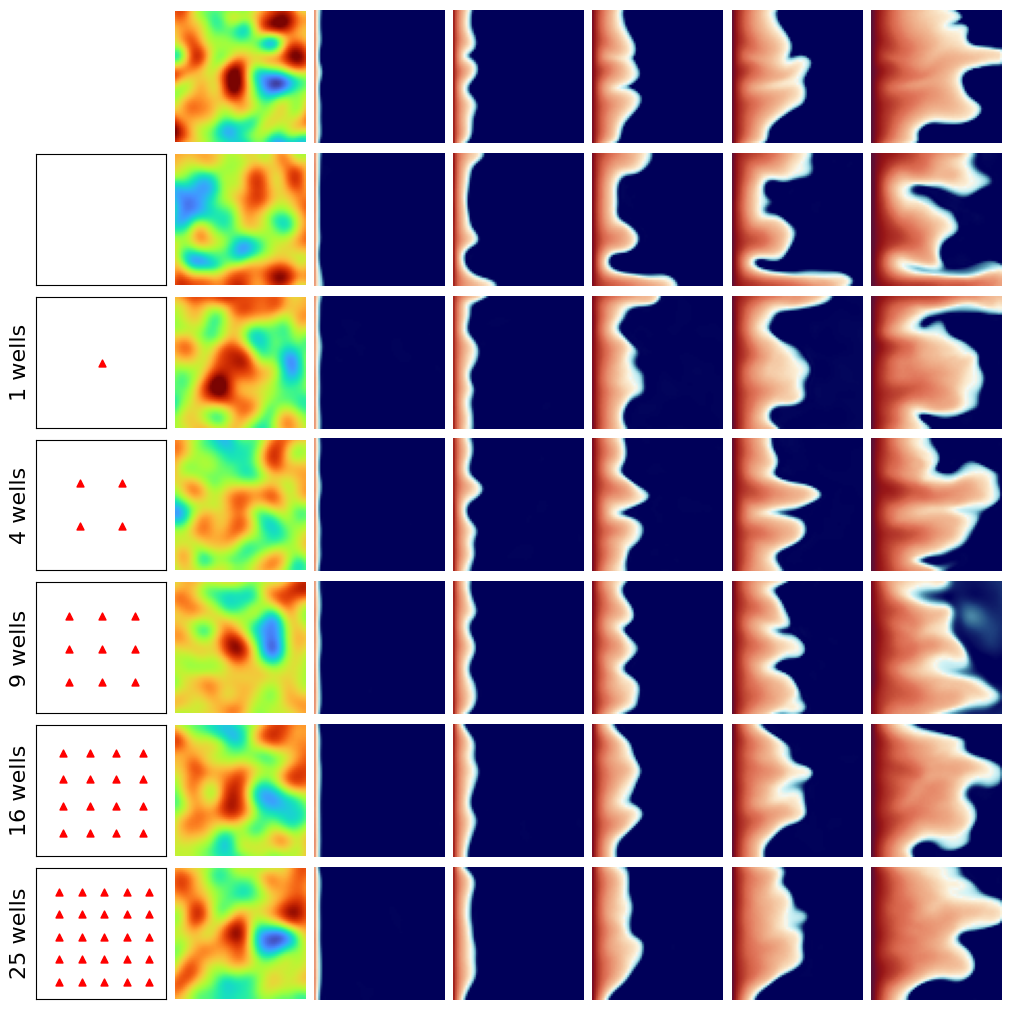

In [18]:
ts = [3, 12, 25, 38, 63]

fig, ax = plt.subplots(7, 7, figsize=(10, 10), layout='constrained')
ax[0,0].imshow(np.zeros((64,64)), cmap='Greys')
ax[0,0].axis('off')
ax[0,1].imshow(ref[0, :, :, 2], vmin=1.5, vmax=6.5, cmap='turbo')
ax[0,1].axis('off')
for j in range(2, 7):
    ax[0,j].axis('off')
    ax[0,j].imshow(ref[ts[j-2], :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)

ax[1,0].imshow(np.zeros((64,64)), cmap='Greys')
ax[1,0].axis('on')
ax[1,0].set_xticks([])
ax[1,0].set_yticks([])
ax[1,1].imshow(np.mean(well_0_pt[5, :, :, :, 2], axis=0), vmin=1.5, vmax=6.5, cmap='turbo')
ax[1,1].axis('off')

for j in range(2, 7):
    ax[1,j].axis('off')
    ax[1,j].imshow(well_0_pt[5, ts[j-2], :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)

for i in range(2, 7):
    ax[i,0].imshow(np.zeros((64,64)), cmap='Greys')
    y, x = zip(*wells[i-2])
    ax[i,0].scatter(x, y, color='red', marker='^', s=25)
    if i == 1:
        ax[i,0].set_ylabel(f'{(i-1)**2} well', fontsize=16)
    else:
        ax[i,0].set_ylabel(f'{(i-1)**2} wells', fontsize=16)
    ax[i,0].set_xticks([])
    ax[i,0].set_yticks([])
    
    ax[i,1].imshow(np.mean(wells_npy[i-2][0, :, :, :, 2], axis=0), vmin=1.5, vmax=6.5, cmap='turbo')
    ax[i,1].axis('off')
    
    
    for j in range(2, 7):
        ax[i,j].axis('off')
        ax[i,j].imshow(wells_npy[i-2][0, ts[j-2], :, :-1, 1], vmin=0, vmax=0.6, cmap=mycmap)
    
plt.savefig('conditional_outputs/figs_sensitivity/[rebuttle]sparse_psk.pdf', bbox_inches='tight')
plt.show()

In [19]:
from skimage.metrics import structural_similarity as ssim

def compute_K_ssim(REF, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_value = ssim(REF[0, :, :, 2], np.mean(gen[i, :, :, :, 2], axis=0), data_range=REF[0, :, :, 2].max() - REF[0, :, :, 2].min())
        ssim_values.append(ssim_value)
    return np.array(ssim_values)

def compute_temporal_sg_ssim(REF, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(REF[t, :, :, 1], gen[i, t, :, :, 1], data_range=REF[t, :, :, 1].max() - REF[t, :, :, 1].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)

def compute_temporal_p_ssim(REF, gen):
    ssim_values = []
    for i in range(gen.shape[0]):
        ssim_t_values = []
        for t in range(gen.shape[1]):
            ssim_value = ssim(REF[t, :, :, 0], gen[i, t, :, :, 0], data_range=REF[t, :, :, 0].max() - REF[t, :, :, 0].min())
            ssim_t_values.append(ssim_value)
        ssim_values.append(np.array(ssim_t_values))
    return np.array(ssim_values)

In [20]:
all_wells_npy = [well_0_pt, well_1_pt, well_4_pt, well_9_pt, well_16_pt, well_25_pt]

ssim_k = []
for w in all_wells_npy:
    ssim_k.append(compute_K_ssim(ref, w))
ssim_k = np.array(ssim_k)
print(f"SSIM K shape: {ssim_k.shape}")

SSIM K shape: (6, 10)


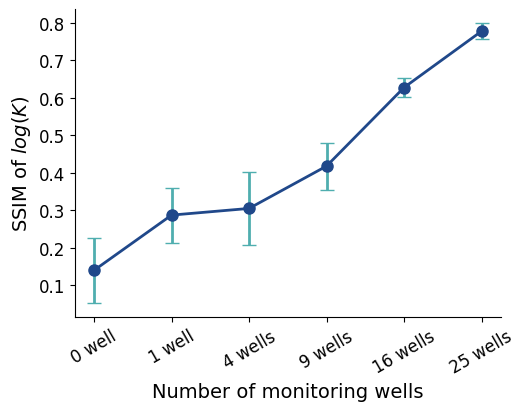

In [24]:
plt.figure(figsize=(5.5, 4))
plt.errorbar(range(1, 7), np.mean(ssim_k, axis=1), yerr=np.std(ssim_k, axis=1), 
             fmt='o-', color='#20488a', ecolor='#4faeaf', elinewidth=2, capsize=5, linewidth=2, markersize=8)
plt.xticks(range(1, 7), ['0 well', '1 well', '4 wells', '9 wells', '16 wells', '25 wells'], fontsize=12, rotation=30)
# plt.ylim(0.2, 0.9)
plt.yticks(fontsize=12)
plt.xlabel('Number of monitoring wells', fontsize=14)
plt.ylabel('SSIM of $log(K)$', fontsize=14)
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

plt.savefig('conditional_outputs/figs_sensitivity/[rebuttle]sparse_ps_ssim_k.pdf', bbox_inches='tight')

In [26]:
all_wells_npy = [well_0_pt, well_1_pt, well_4_pt, well_9_pt, well_16_pt, well_25_pt]

ssim_sg = []
for w in all_wells_npy:
    ssim_sg.append(compute_temporal_sg_ssim(ref, w))
ssim_sg = np.array(ssim_sg)
print(f"SSIM Sg shape: {ssim_sg.shape}")

SSIM Sg shape: (6, 10, 64)


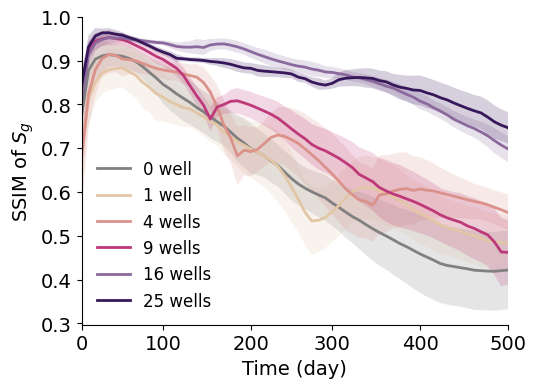

In [27]:
def compute_mean_std(data):
    mean = np.mean(data, axis=0)
    std = np.std(data, axis=0)
    return mean, std
def plot_line_and_fill(data, color, legend_label):
    mean, std = compute_mean_std(data)
    plt.plot(range(64), mean, color=color, linewidth=2, ls='-', label=legend_label)
    plt.fill_between(range(64), mean - std, mean + std, color=color, alpha=0.2, edgecolor='none')

plt.figure(figsize=(5.5, 4))
palette = ["#36185AFF", "#8B699EFF", '#BE3979FF', '#DB928AFF', '#E2C6A6FF', 'gray']
labels = ['0 well', '1 well', '4 wells', '9 wells', '16 wells', '25 wells']
for i in range(len(ssim_sg)):
    plot_line_and_fill(ssim_sg[i], palette[::-1][i], legend_label=labels[i])
    
ax = plt.gca()
ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)

labels = [0, 100, 200, 300, 400, 500]
positions = [int(x * 63 / 500) for x in labels]
plt.xticks(ticks=positions, labels=[str(x) for x in labels])
plt.xticks(fontsize=14)
plt.yticks(fontsize=14)
plt.xlim(0, 63)
plt.ylim(top=1)
plt.xlabel('Time (day)', fontsize=14)
plt.ylabel('SSIM of $S_g$', fontsize=14)
plt.legend(loc='lower left', frameon=False, fontsize=12)

plt.savefig('conditional_outputs/figs_sensitivity/[rebuttle]sparse_psk_ssim_sg.pdf', bbox_inches='tight')